In [14]:
import jax
import jax.numpy as np
from jax import jit, grad, lax
import matplotlib.pyplot as plt

# ============================================================
# GRID AND DATA
# ============================================================
N = 128
L = 2 * np.pi
h = L / N
x = np.linspace(0.0, L, N, endpoint=False)

poisson_iterations = 75
poisson_solver_tolerance = 1e-6
anderson_steps = 4

gradient_descent_iterations = 2*10**4
gradient_descent_tolerance = 1e-5

# ============================================================
# REFERENCE DENSITIES
# ============================================================
def rho_ref_1(x):
    c = np.pi
    a = 0.75 * np.pi
    p = 2.0
    dist = np.abs(x - c)
    denom = np.clip(1.0 - (dist / a) ** p, 1e-6, None)
    r = np.exp(-1.0 / denom)
    Z = h * np.sum(r)
    return r / Z

def rho_ref_2(x):
    r = 2.0 + np.cos(x - np.pi)
    Z = h * np.sum(r)
    return r / Z

def rho_ref_3(x):
    mu1, mu2 = np.pi / 2, 3 * np.pi / 2
    sigma = 0.4
    r = np.exp(-0.5 * ((x - mu1) / sigma)**2) + np.exp(-0.5 * ((x - mu2) / sigma)**2)
    Z = h * np.sum(r)
    return r / Z

def rho_ref_4(x):
    key = jax.random.PRNGKey(0)
    noise = jax.random.normal(key, shape=x.shape)
    r = np.abs(jax.numpy.fft.ifft(
        jax.numpy.fft.fft(noise) * (1.0 / (1 + np.arange(N)**2))
    ).real)
    Z = h * np.sum(r)
    return r / Z

rho_ref_fns = [rho_ref_1, rho_ref_2, rho_ref_3, rho_ref_4]

# ============================================================
# LAPLACIAN
# ============================================================
def laplacian(phi):
    return (np.roll(phi, -1) - 2.0 * phi + np.roll(phi, 1)) / h**2

# ============================================================
# PRECONDITIONER
# ============================================================
k = 2 * np.pi * np.fft.fftfreq(N, d=h)

def precondition(g, gamma=5e-2):
    g_hat = np.fft.fft(g)
    denom = 1.0 + gamma * k**2
    return np.real(np.fft.ifft(g_hat / denom))

# ============================================================
# DENSITY
# ============================================================
def rho(u, phi):
    z = np.exp(-u - phi)
    return z / (h * np.sum(z))

# ============================================================
# POISSON SOLVER
# ============================================================
@jit
def solve_poisson(rhs):
    rhs_hat = np.fft.fft(rhs)
    k = 2 * np.pi * np.fft.fftfreq(N, d=h)

    denom = k**2
    denom = denom.at[0].set(1.0)

    phi_hat = rhs_hat / denom
    phi_hat = phi_hat.at[0].set(0.0)

    return np.real(np.fft.ifft(phi_hat))

# ============================================================
# PICARD FIXED POINT WITH ANDERSON ACCELERATION AND DAMPING 
# ============================================================
@jit
def solve_phi(u, phi_init,
              n_iter=poisson_iterations,
              m=anderson_steps,
              beta=0.9,
              eps=1e-8,
              tol=poisson_solver_tolerance):

    def body(state):
        i, phi, X, F, res = state

        r = rho(u, phi)
        rhs = r - 1.0 / L

        phi_new = solve_poisson(rhs)
        phi_new = phi_new - np.mean(phi_new)

        f = phi_new - phi

        X = np.roll(X, -1, axis=0).at[-1].set(phi)
        F = np.roll(F, -1, axis=0).at[-1].set(f)

        mk = np.minimum(i + 1, m)

        A = (F.reshape(m, -1) @ F.reshape(m, -1).T)
        A = A + eps * np.eye(m)

        mask = (np.arange(m) >= (m - mk)).astype(phi.dtype)
        A = A * mask[:, None] * mask[None, :]
        A = A + (1.0 - mask)[:, None] * np.eye(m)

        coeffs = np.linalg.solve(A, mask)
        coeffs = coeffs / (np.sum(coeffs) + eps)

        phi_next = np.sum(coeffs[:, None] * (X + beta * F), axis=0)
        phi_next = phi_next - np.mean(phi_next)

        res = np.linalg.norm(phi_next - phi)

        return (i + 1, phi_next, X, F, res)

    def cond(state):
        i, phi, X, F, res = state
        return (i < n_iter) & (res > tol)

    X0 = np.tile(phi_init[None, :], (m, 1))
    F0 = np.zeros_like(X0)

    init = (0, phi_init, X0, F0, 1e9)

    i, phi_final, X, F, res = lax.while_loop(cond, body, init)

    return phi_final, res

# ============================================================
# ENERGY 
# ============================================================
def energy(u, phi, alpha):
    r = rho(u, phi)

    kl = h * np.sum(r * np.log((r + 1e-9) / (rho_ref_vals + 1e-9)))

    grad_phi = (np.roll(phi, -1) - np.roll(phi, 1)) / (2*h)
    dirichlet = h * np.sum(grad_phi**2)

    grad_u = (np.roll(u, -1) - np.roll(u, 1)) / (2 * h)
    reg = alpha * h * np.sum(u**2 + grad_u**2)

    return kl + reg + 1e-3 * dirichlet

# ============================================================
# SPECTRAL RADIUS
# ============================================================
def spectral_radius_T(u, phi, n_power=6):

    def T(phi):
        r = rho(u, phi)
        return solve_poisson(r - 1.0 / L)

    v = np.ones_like(phi)

    def step(v, _):
        v = v / (np.linalg.norm(v) + 1e-12)
        v = jax.jvp(T, (phi,), (v,))[1]
        return v, None

    v, _ = lax.scan(step, v, None, length=n_power)

    v = v / (np.linalg.norm(v) + 1e-12)
    v = jax.jvp(T, (phi,), (v,))[1]

    return np.linalg.norm(v)

# ============================================================
# LINE SEARCH
# ============================================================
def line_search(u, phi, g, alpha, init_lr=0.5, beta=0.5, c=1e-4, max_backtracks=6):

    gnorm2 = np.sum(g * g)
    E0 = energy(u, phi, alpha)

    def cond_fun(state):
        i, lr, ok = state
        return (i < max_backtracks) & (~ok)

    def body_fun(state):
        i, lr, ok = state

        u_new = u - lr * g
        u_new = u_new - np.mean(u_new)

        phi_new, _ = solve_phi(u_new, phi)

        E_new = energy(u_new, phi_new, alpha)

        ok = E_new <= E0 - c * lr * gnorm2
        lr = np.where(ok, lr, lr * beta)

        return (i + 1, lr, ok)

    _, lr_final, _ = lax.while_loop(cond_fun, body_fun, (0, init_lr, False))
    return lr_final

# ============================================================
# OPTIMIZER
# ============================================================
def optimize(u0, alpha, lr=1.0,
             steps=gradient_descent_iterations,
             tol=gradient_descent_tolerance):

    phi0 = np.zeros_like(u0)

    gnorms = np.zeros((steps,))
    energies_buf = np.zeros((steps,))
    phi_res_buf = np.zeros((steps,))
    spectral_buf = np.zeros((steps,))

    def cond(state):
        i, u, phi, gnorm, _, _, _, _ = state
        return (i < steps) & (gnorm > tol)

    def body(state):
        i, u, phi, _, gnorms_buf, res_buf, energies_buf, spectral_buf = state

        g_raw = grad_energy(u, phi, alpha)
        g = precondition(g_raw)
        gnorm = np.sqrt(np.sum(g * g))

        E = energy(u, phi, alpha)

        lr_adapt = line_search(u, phi, g, alpha, init_lr=lr)

        u_new = u - lr_adapt * g
        phi_new, phi_res = solve_phi(u_new, phi)

        rho_J = spectral_radius_T(u_new, phi_new)
        spectral_buf = spectral_buf.at[i].set(rho_J)

        energies_buf = energies_buf.at[i].set(E)
        gnorms_buf = gnorms_buf.at[i].set(gnorm)
        res_buf = res_buf.at[i].set(phi_res)

        return (i + 1, u_new, phi_new, gnorm,
                gnorms_buf, res_buf, energies_buf, spectral_buf)

    init = (0, u0, phi0, np.array(1.0),
            gnorms, phi_res_buf, energies_buf, spectral_buf)

    i, u, phi, gnorm, gnorms_out, res_out, energies_out, spectral_out = \
        lax.while_loop(cond, body, init)

    return u, phi, gnorms_out[:i], res_out[:i], energies_out[:i], spectral_out[:i]

# ============================================================
# RUN: over rho_refs × alphas
# ============================================================
alphas = np.array([1e-3, 1e-2, 0.1, 0.35, 0.9])

results = []

u0 = np.zeros_like(x)

for rho_fn in rho_ref_fns:

    rho_ref_vals = rho_fn(x)
    grad_energy = jit(grad(energy, argnums=0))  # recompile per rho_ref

    alpha_results = []

    for alpha in alphas:
        u_opt, phi_opt, gnorms, phi_res, energies, spectral = optimize(u0, alpha)
        rho_opt = rho(u_opt, phi_opt)

        alpha_results.append(
            [alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals]
        )

    results.append(alpha_results)

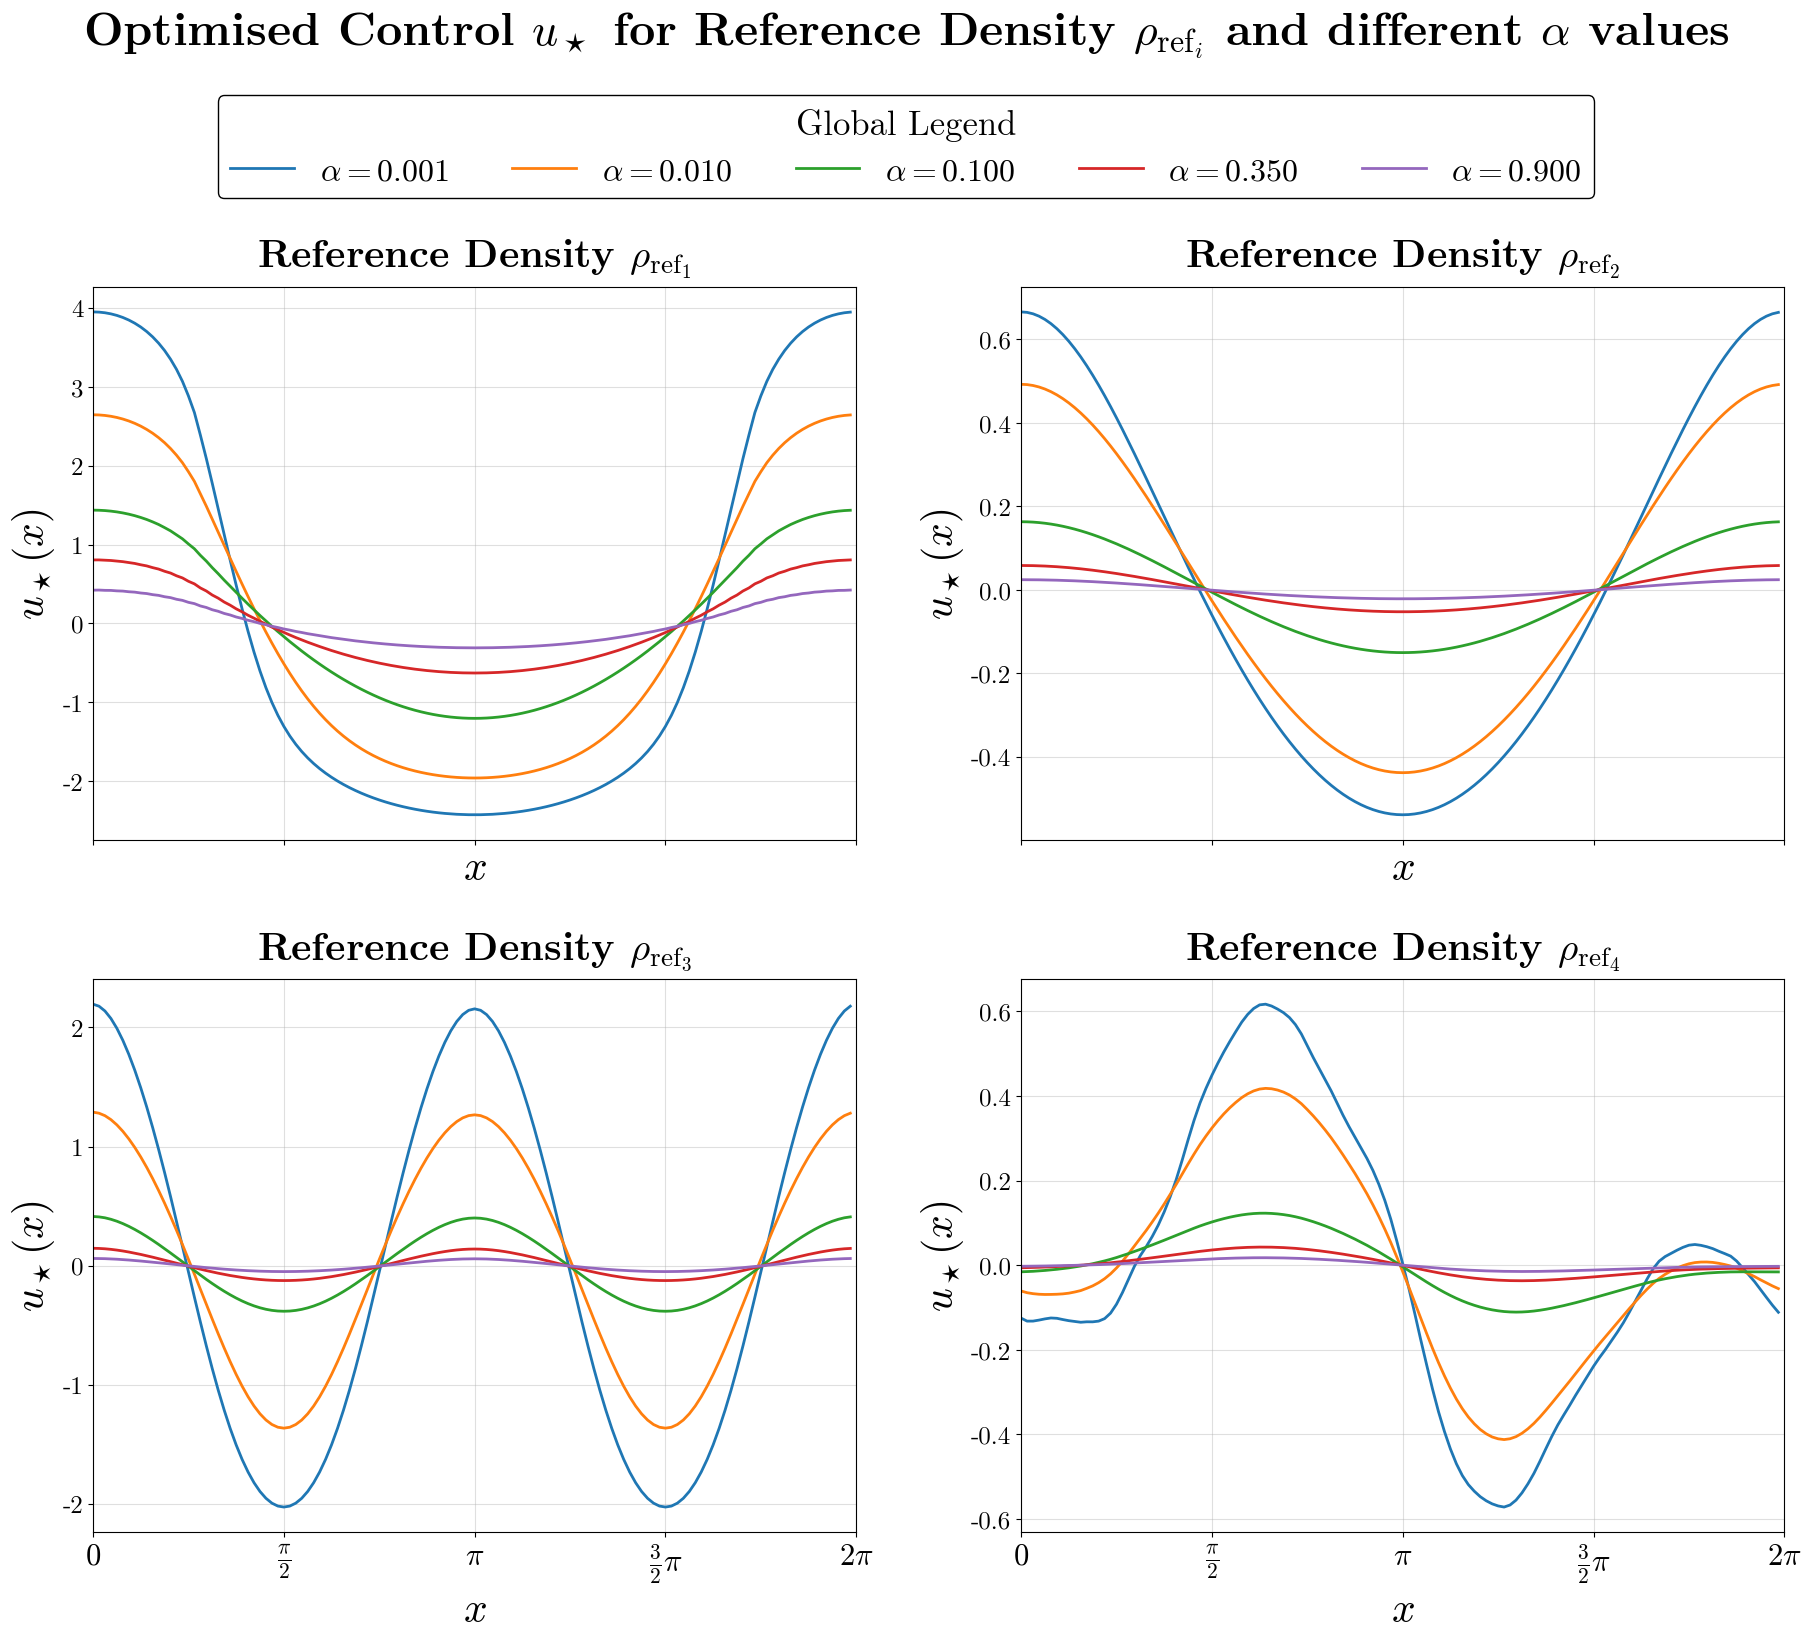

In [15]:
# ================================================================
# PLOTS - SETTINGS
# ================================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["CMU Serif"],
    "mathtext.fontset": "cm",  
})
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["lines.linewidth"] = 2


# ================================================================
# PLOTS - OPTIMAL EXTERNAL FIELD
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)

fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

y_buffer = 0.05

for i, ax in enumerate(axes):
    results_i = results[i]
    y_vals_panel = []

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        ax.plot(x, u_opt, label=fr"$\alpha={alpha:.3f}$")
        y_vals_panel.append(u_opt)

    y_all = np.concatenate(y_vals_panel)
    y_min, y_max = y_all.min(), y_all.max()
    y_pad = (y_max - y_min) * y_buffer if y_max > y_min else 1e-3

    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$x$", fontsize=30)
    ax.set_ylabel(r"$u_\star(x)$", fontsize=30)

    ax.grid(True, alpha=0.4)

# x-ticks only on first subplot
axes[0].set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
axes[0].set_xticklabels(
    [r"$0$", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3}{2}\pi$", r"$2\pi$"]
)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

# GLOBAL LEGEND
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Optimised Control $u_\star$ for Reference Density $\rho_{\mathrm{ref}_i}$ and different $\alpha$ values",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()


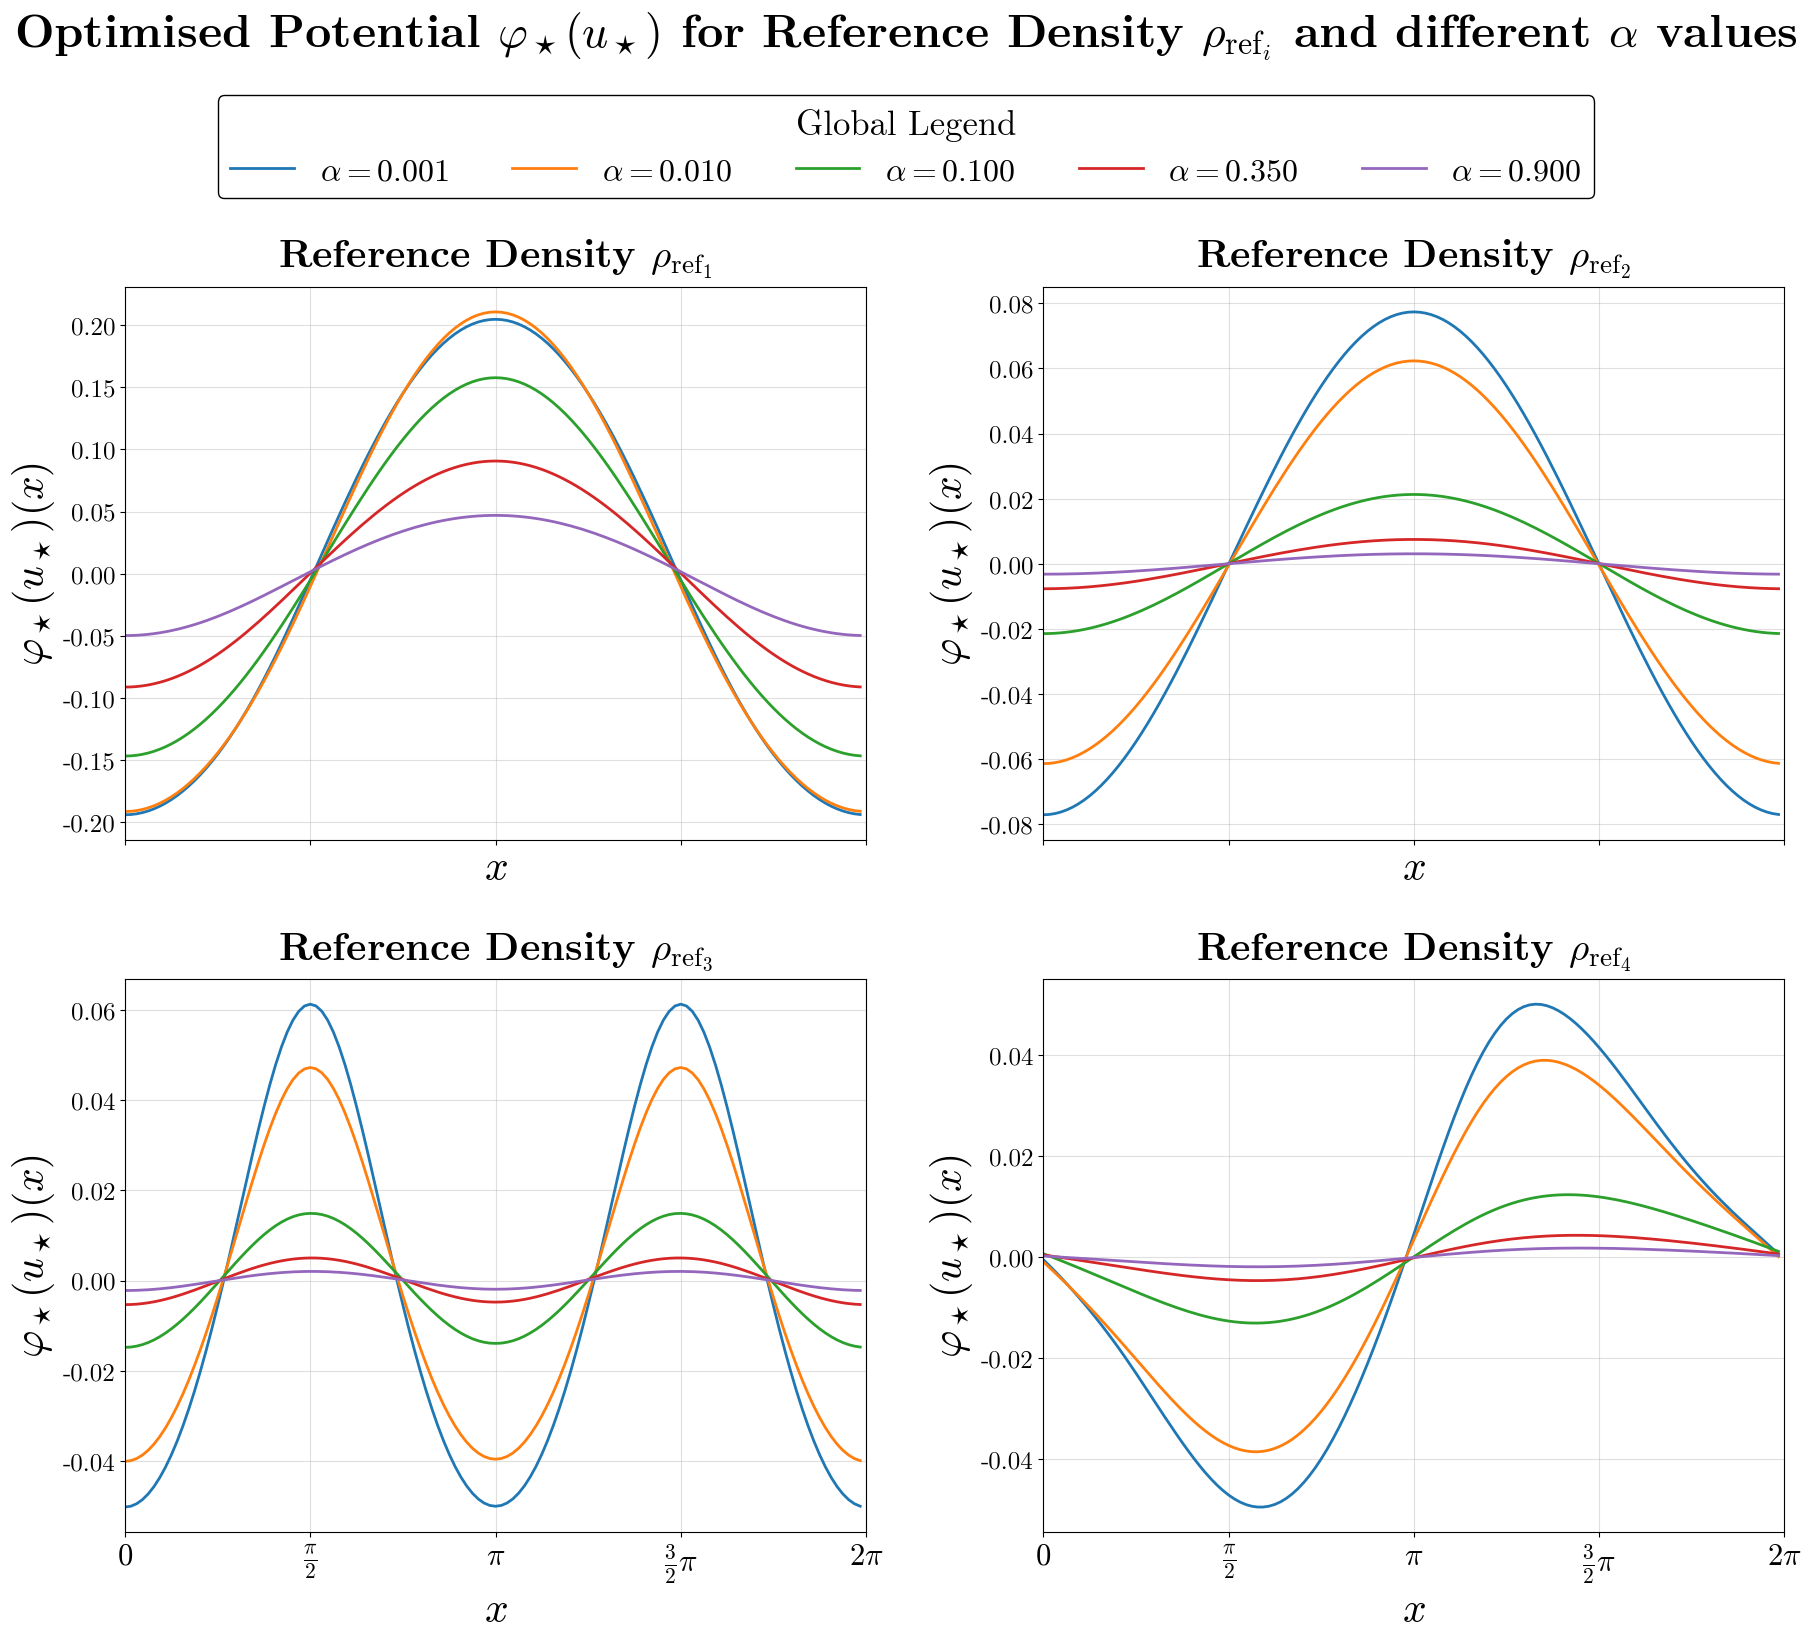

In [16]:
# ================================================================
# PLOTS - SELF-CONSISTENT POTENTIAL
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

y_buffer = 0.05

for i, ax in enumerate(axes):
    results_i = results[i]
    y_vals_panel = []

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        ax.plot(x, phi_opt, label=fr"$\alpha={alpha:.3f}$")
        y_vals_panel.append(phi_opt)

    y_all = np.concatenate(y_vals_panel)
    y_min, y_max = y_all.min(), y_all.max()
    y_pad = (y_max - y_min) * y_buffer if y_max > y_min else 1e-3

    ax.set_xlim(x.min(), x.max())
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )
    ax.set_xlabel(r"$x$", fontsize=30)
    ax.set_ylabel(r"$\varphi_\star(u_\star)(x)$", fontsize=30)

    ax.grid(True, alpha=0.4)


axes[0].set_xticks([0, np.pi/2, np.pi, 3*np.pi/2, 2*np.pi])
axes[0].set_xticklabels(
    [r"$0$", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3}{2}\pi$", r"$2\pi$"]
)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

# GLOBAL LEGEND
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Optimised Potential $\varphi_\star(u_\star)$ for Reference Density $\rho_{\mathrm{ref}_i}$ and different $\alpha$ values",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()

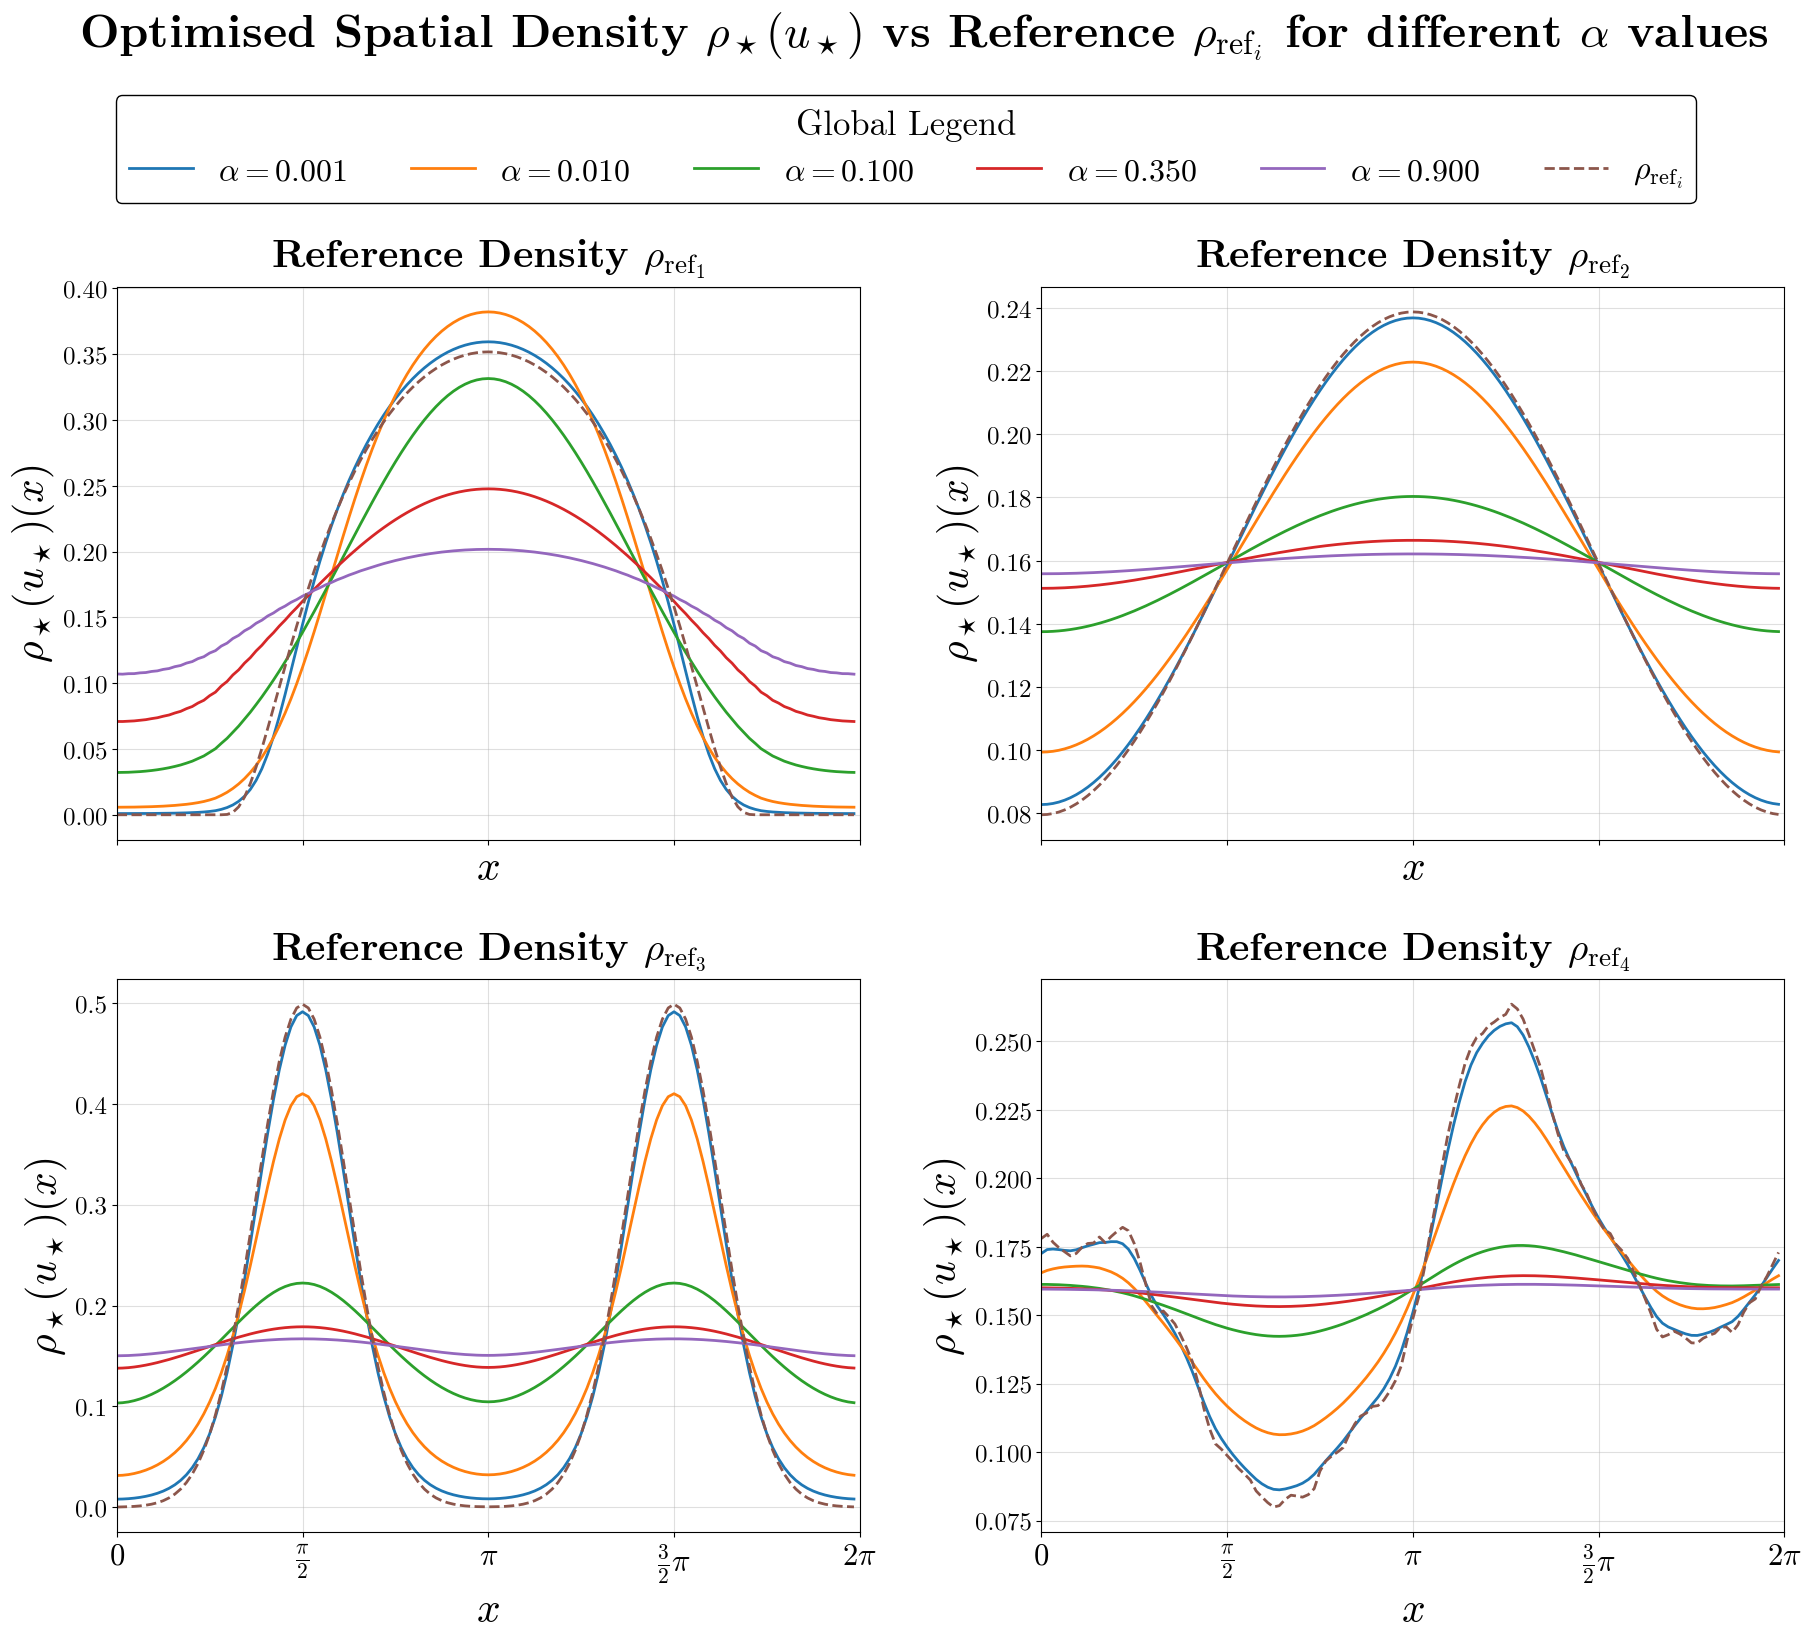

In [17]:
# ================================================================
# PLOTS - SPATIAL DENSITY
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

y_buffer = 0.05

for i, ax in enumerate(axes):
    results_i = results[i]
    y_vals_panel = []

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        ax.plot(x, rho_opt, label=fr"$\alpha={alpha:.3f}$")
        y_vals_panel.append(rho_opt)

    ax.plot(x, rho_ref_vals, "--", label=r"$\rho_{{\mathrm{{ref}}_{i}}}$")
    y_vals_panel.append(rho_ref_vals)

    y_all = np.concatenate(y_vals_panel)
    y_min, y_max = y_all.min(), y_all.max()
    y_pad = (y_max - y_min) * y_buffer if y_max > y_min else 1e-3

    ax.set_xlim(0, L)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.set_title(fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$", fontsize=28, fontweight="bold",y=1.02)
    ax.set_xlabel(r"$x$", fontsize=30)
    ax.set_ylabel(r"$\rho_\star(u_\star)(x)$", fontsize=30)

    ax.grid(True, alpha=0.4)

axes[0].set_xticks([0,np.pi/2,np.pi,3/2*np.pi, 2*np.pi])
axes[0].set_xticklabels([r"$0$", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3}{2}\pi$",  r"$2\pi$"])

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

# GLOBAL LEGEND
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Optimised Spatial Density $\rho_\star(u_\star)$ vs Reference $\rho_{{\mathrm{ref}}_{i}}$ for different $\alpha$ values",
    fontsize=33,
    x=0.51,
    y=1.16,
    fontweight="bold"
)

plt.show()

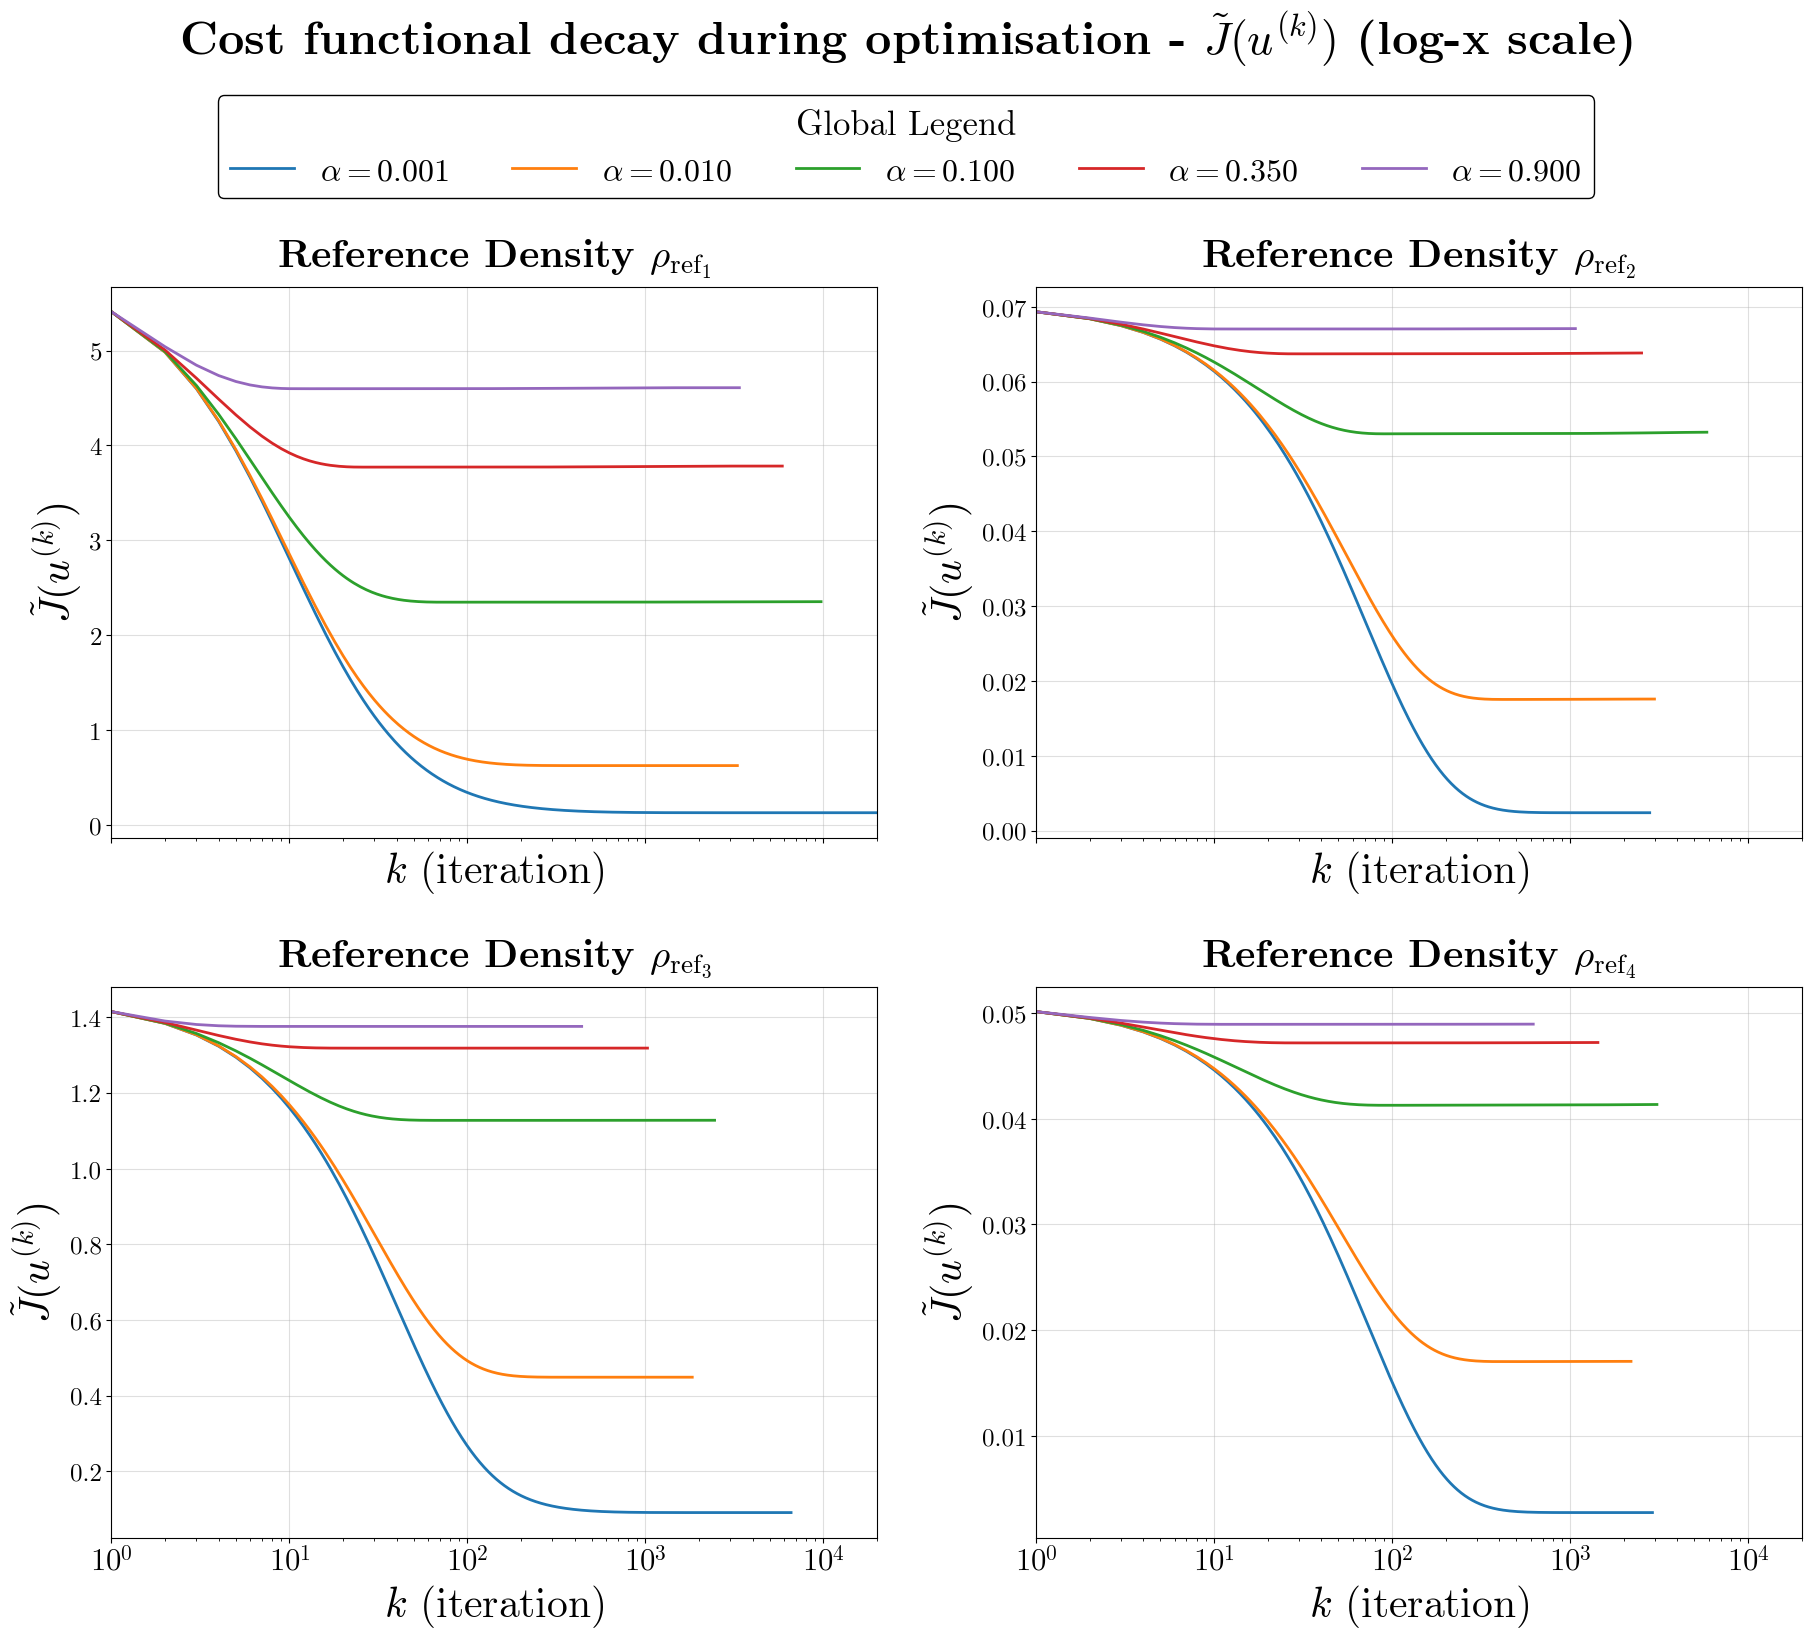

In [18]:

# ================================================================
# PLOTS - COST FUNCTIONAL DECAY
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

for i, ax in enumerate(axes):
    results_i = results[i]

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        it = np.arange(1, len(energies) + 1)

        ax.plot(it, energies, label=fr"$\alpha={alpha:.3f}$")

    ax.set_xscale("log")
    ax.set_xlim(1, gradient_descent_iterations)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$k$ (iteration)", fontsize=30)
    ax.set_ylabel(r"$\tilde{J}(u^{(k)})$", fontsize=30)

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Cost functional decay during optimisation - $\tilde{J}(u^{(k)})$ (log-x scale)",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()



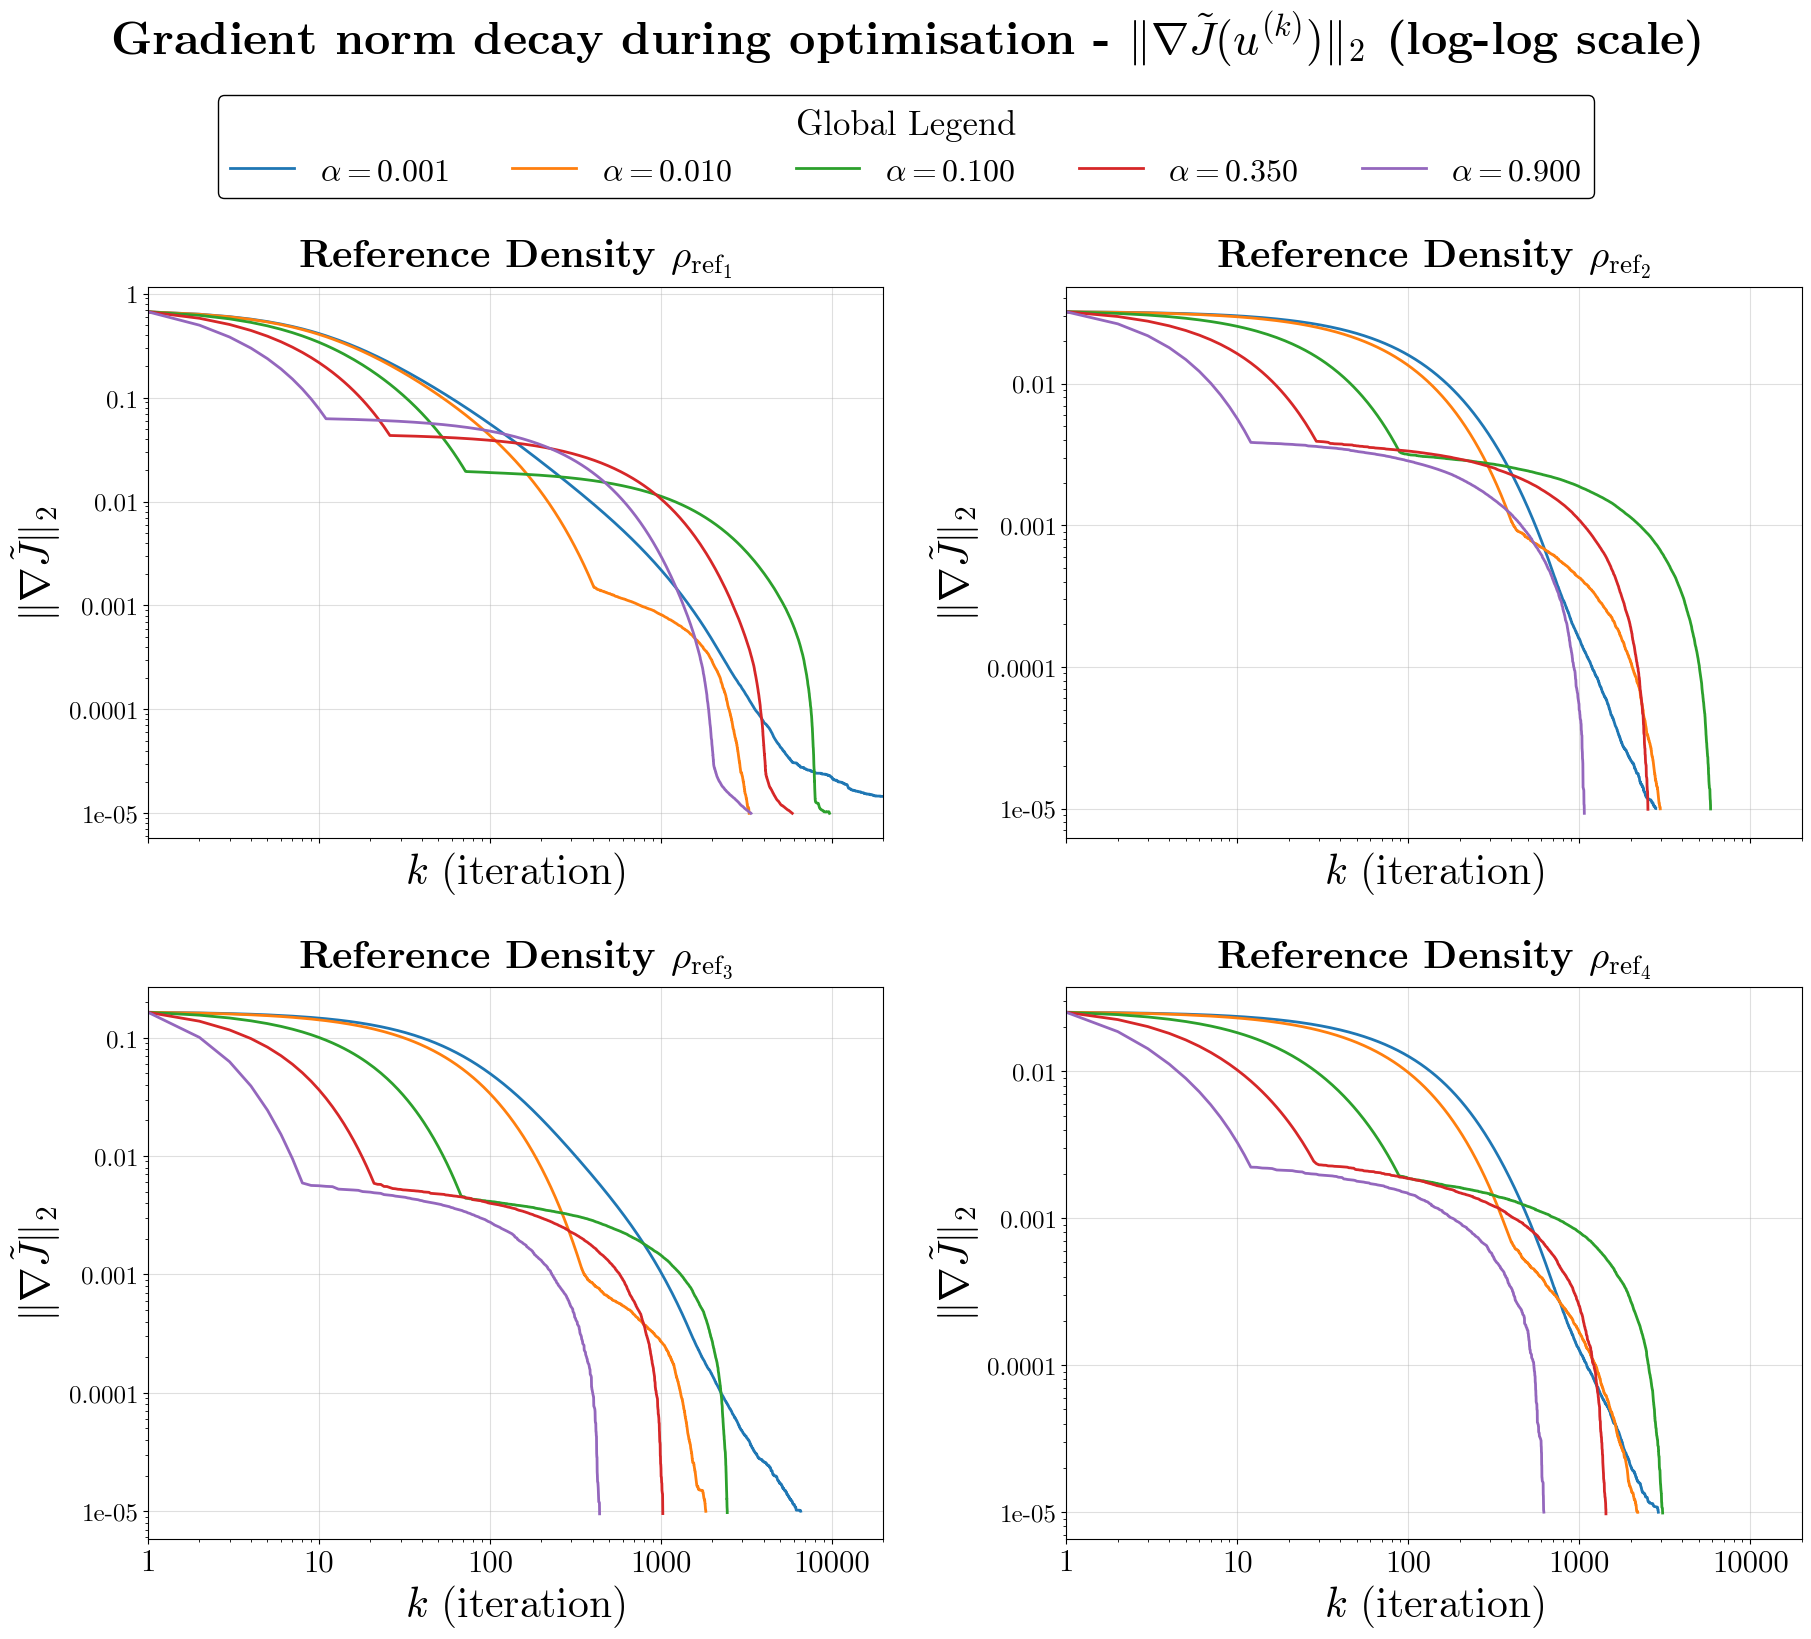

In [19]:
# ================================================================
# PLOTS - DECAY OF THE GRADIENT OF THE FUNCTIONAL (L2 NORM)
# ================================================================

import matplotlib.ticker as mticker

def clean_fmt(x, pos):
    return f"{x:g}"   # forces normal ASCII formatting

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

for i, ax in enumerate(axes):
    results_i = results[i]

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        it = np.arange(1, len(gnorms) + 1)

        ax.plot(it, gnorms, label=fr"$\alpha={alpha:.3f}$")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, gradient_descent_iterations)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$k$ (iteration)", fontsize=30)
    ax.set_ylabel(r"$\|\nabla\tilde{J}\|_2$", fontsize=30)

    ax.grid(True, alpha=0.4)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Gradient norm decay during optimisation - $\|\nabla\tilde{J}(u^{(k)})\|_2$ (log-log scale)",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()


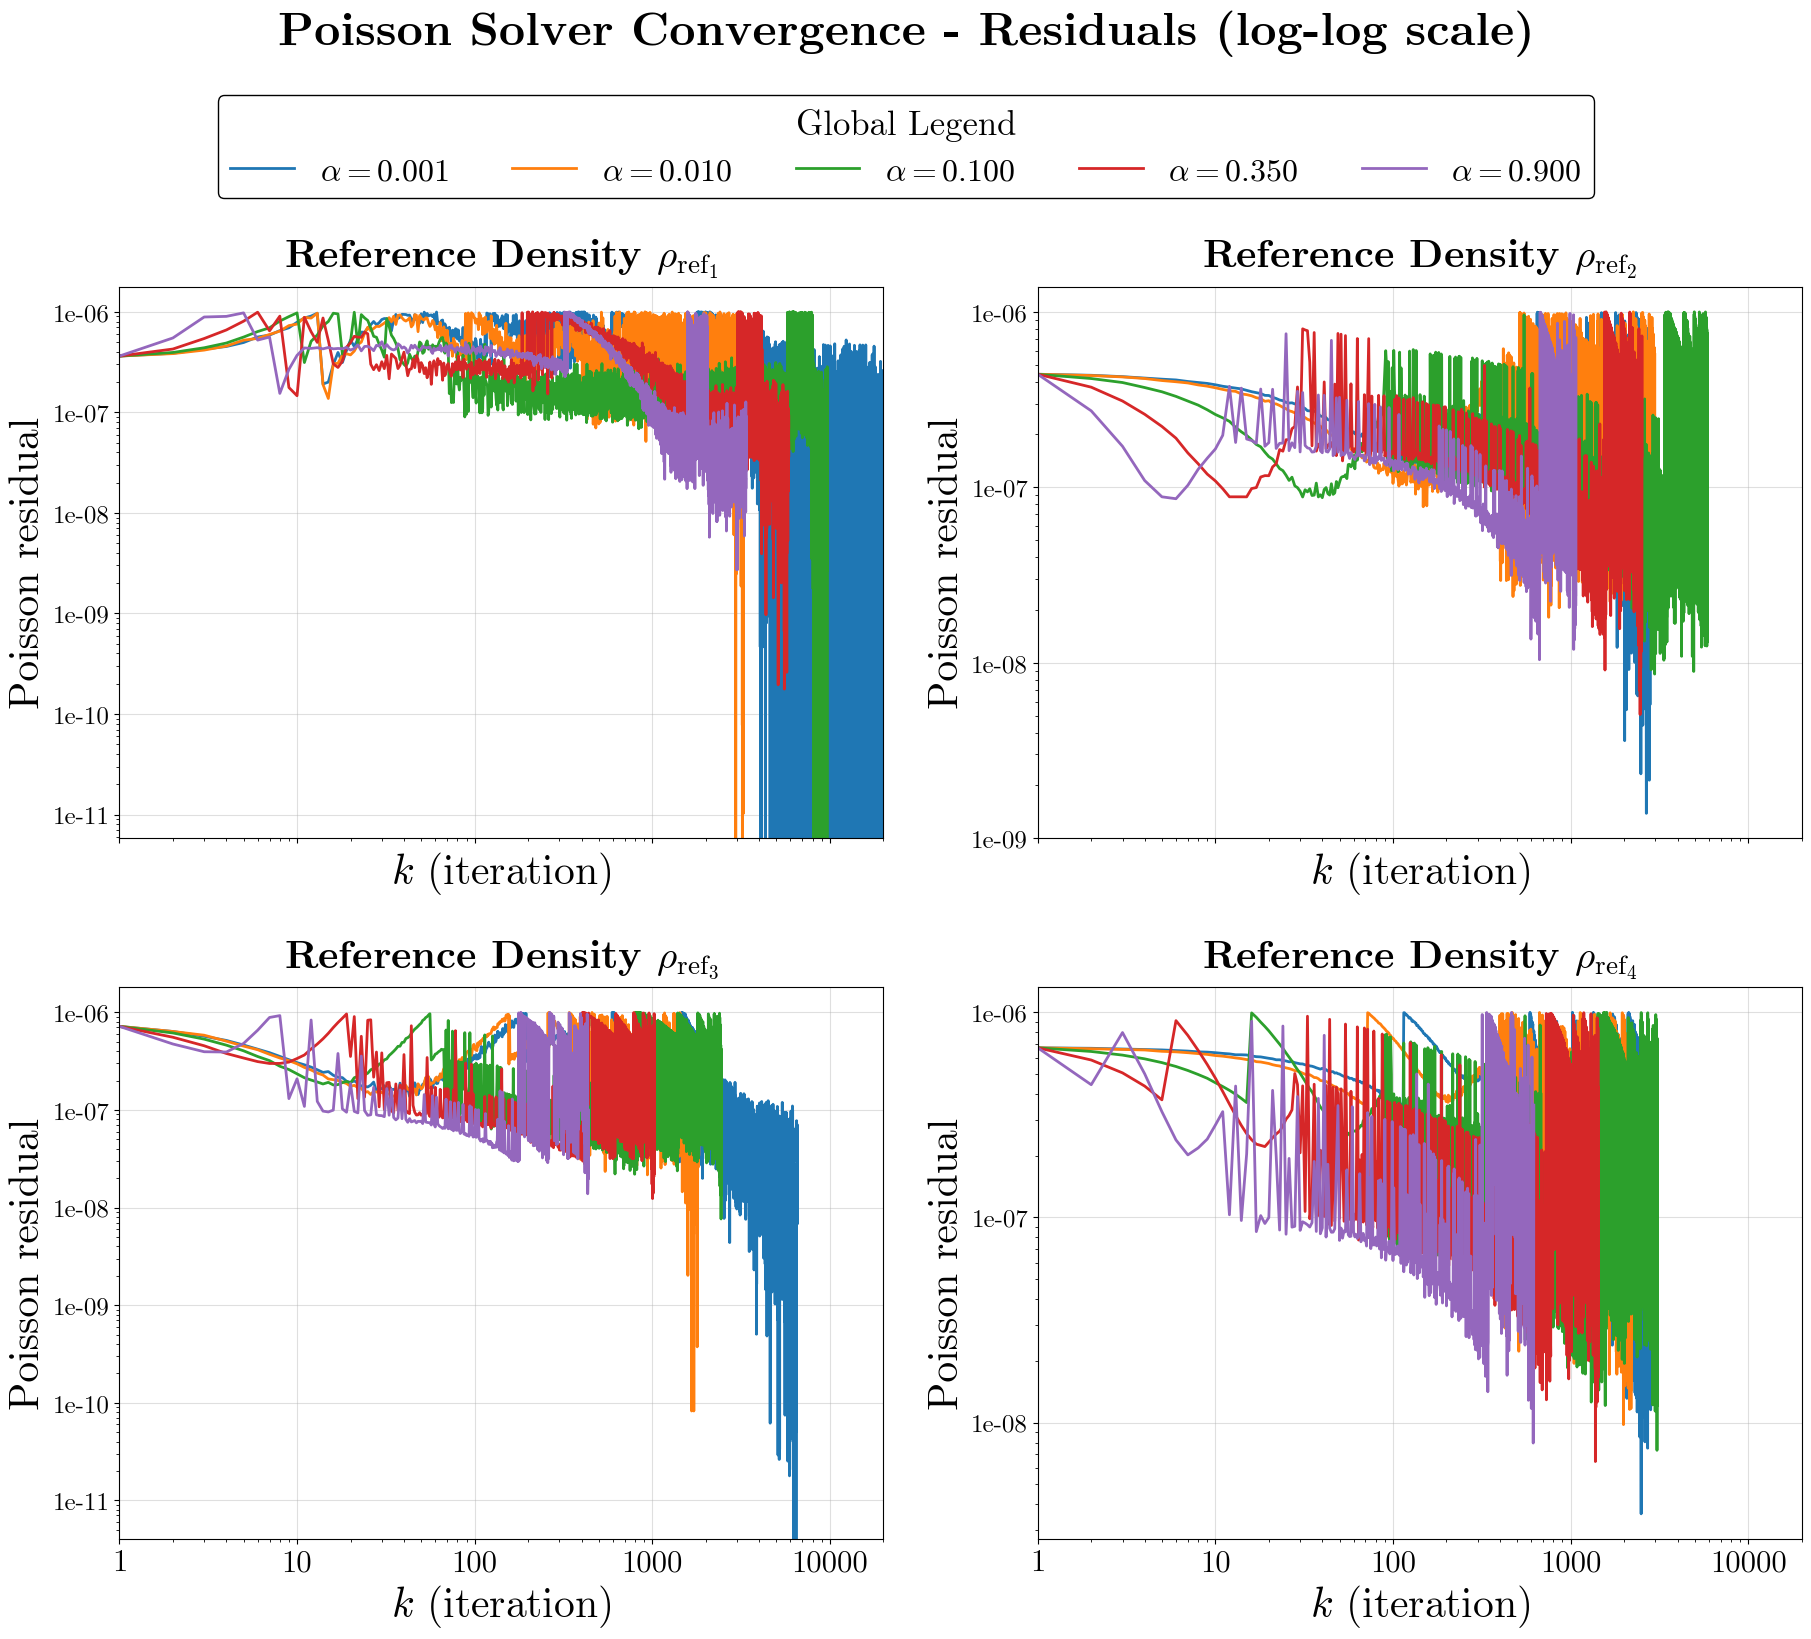

In [20]:
# ================================================================
# PLOTS - POISSON SOLVER CONVERGENCE (RESIDUALS)
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

for i, ax in enumerate(axes):
    results_i = results[i]

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        it = np.arange(1, len(phi_res) + 1)

        ax.plot(it, phi_res, label=fr"$\alpha={alpha:.3f}$")

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(1, gradient_descent_iterations)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$k$ (iteration)", fontsize=30)
    ax.set_ylabel(r"Poisson residual", fontsize=30)

    ax.grid(True, alpha=0.4)

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Poisson Solver Convergence - Residuals (log-log scale)",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()

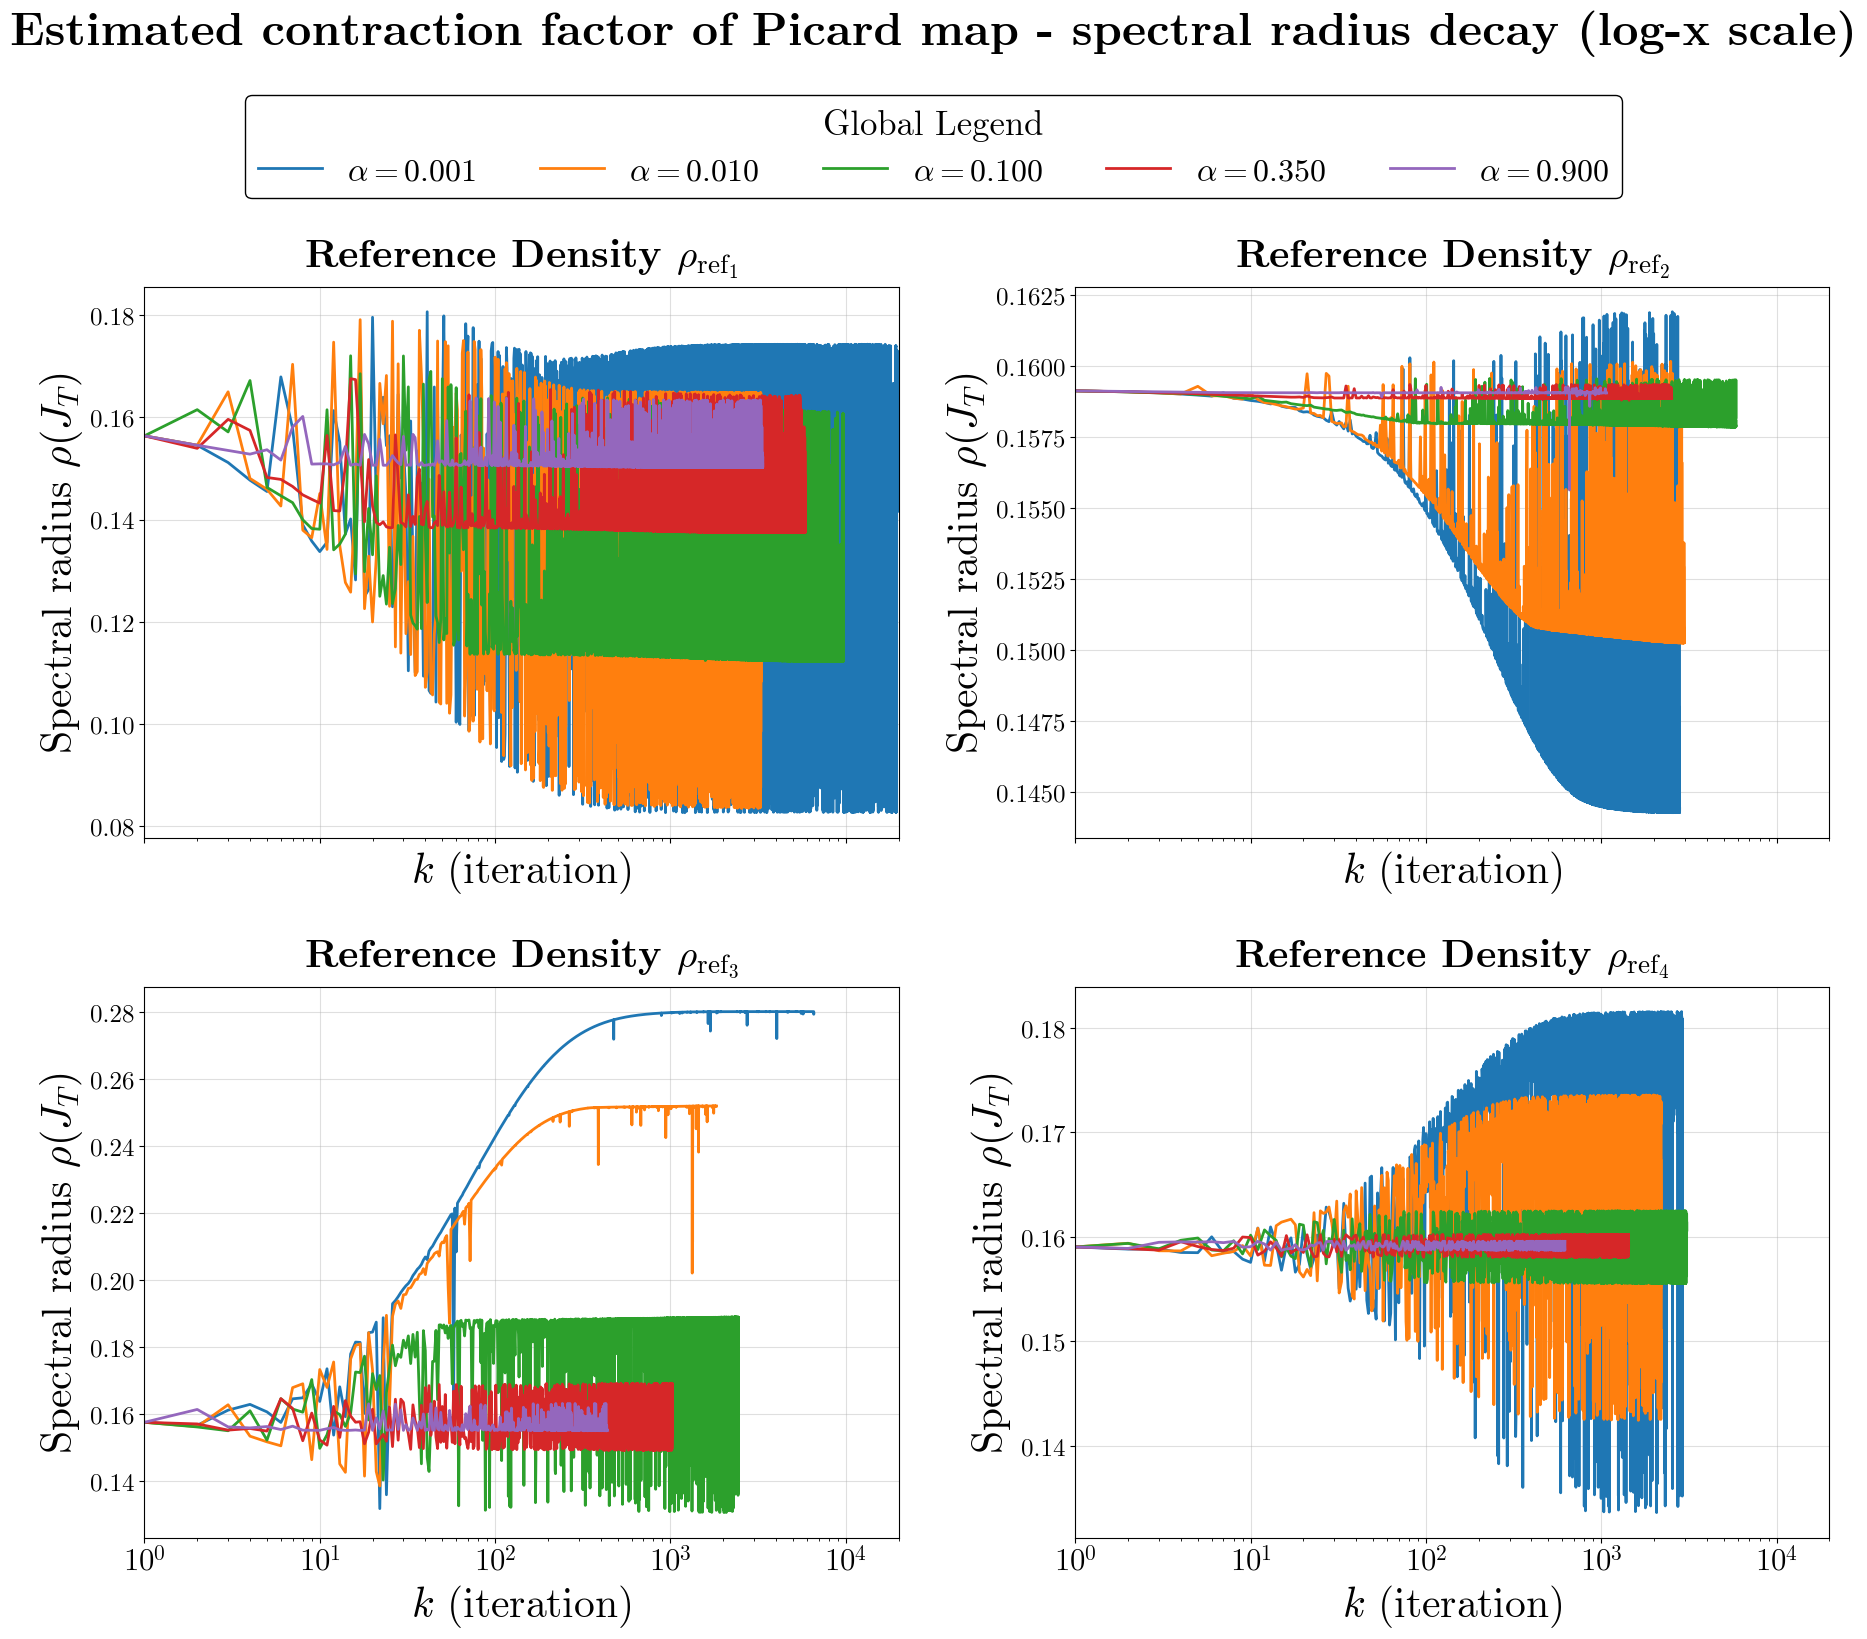

In [21]:
# ================================================================
# PLOTS - SPECTRAL RADIUS (PICARD CONTRACTIVITY)
# ================================================================

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

for i, ax in enumerate(axes):
    results_i = results[i]

    for alpha, u_opt, phi_opt, rho_opt, gnorms, phi_res, energies, spectral, rho_ref_vals in results_i:
        it = np.arange(1, len(spectral) + 1)

        ax.plot(it, spectral, label=fr"$\alpha={alpha:.3f}$")

    ax.set_xscale("log")
    ax.set_xlim(1, gradient_descent_iterations)

    ax.set_title(
        fr"Reference Density $\rho_{{\mathrm{{ref}}_{i+1}}}$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$k$ (iteration)", fontsize=30)
    ax.set_ylabel(r"Spectral radius $\rho(J_T)$", fontsize=30)

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.11),
    ncol=len(labels),
    fontsize=23,
    title_fontsize=25,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Estimated contraction factor of Picard map - spectral radius decay (log-x scale)",
    fontsize=33,
    x=0.5,
    y=1.16,
    fontweight="bold"
)

plt.show()

In [68]:
import numpy as np
from scipy.sparse.linalg import LinearOperator
from scipy.ndimage import gaussian_filter
from scipy.sparse.linalg import eigs
from scipy.linalg import solve_continuous_are
from scipy.sparse.linalg import ArpackNoConvergence
from scipy.linalg import qr
from scipy.linalg import null_space


# -----------------------
# grids
# -----------------------
x = np.linspace(0.0, L, N, endpoint=False)
dx = L / N

Nv = N
V = 10.0
v = np.linspace(-V, V, Nv)
dv = v[1] - v[0]

X, Vv = np.meshgrid(x, v, indexing="ij")

# -----------------------
# noise
# -----------------------
noise_amp = 0.1
noise_state = np.zeros((N,Nv))
tau_noise = 0.5

# -----------------------
# control gains and parameters
# -----------------------
cutoff_param = 0.33
K = 0.25
n_modes_list = [50,50,70,50]

lqr_state_weight = 5e5
lqr_crt_weight = 1
init_cond_param = 3.75

# -----------------------
# time grid
# -----------------------
dt = min(8.5e-5, 0.1 * dv**2)   
steps = int(8.24e4)          


# -----------------------
# Operators
# -----------------------

# Fourier derivative
k = 2*np.pi*np.fft.rfftfreq(N, d=dx)
ik = 1j*k

# Poisson inverse
k2 = k**2
k2[0] = 1.0

inv_k2 = 1/k2
inv_k2[0] = 0.0


# velocity operators
Dv = np.zeros((Nv,Nv))

for i in range(1,Nv-1):
    Dv[i,i+1] =  1/(2*dv)
    Dv[i,i-1] = -1/(2*dv)

Dv[0,0] = -1/dv
Dv[0,1] = 1/dv
Dv[-1,-2] = -1/dv
Dv[-1,-1] = 1/dv


Dvv = np.zeros((Nv,Nv))

for i in range(1,Nv-1):
    Dvv[i,i-1] = 1/dv**2
    Dvv[i,i]   = -2/dv**2
    Dvv[i,i+1] = 1/dv**2

Dvv[0,1]   = 1/dv**2
Dvv[0,2]   = -2/dv**2
Dvv[0,3]   = 1/dv**2
Dvv[-1,-4] = 1/dv**2
Dvv[-1,-3] = -2/dv**2
Dvv[-1,-2] = 1/dv**2


# ==========================================================
# trajectory computation
# ==========================================================
all_results = []
rng = np.random.default_rng()
idx = 0

for result in results:

    print(f"Simulation {idx+1}/{len(results)}:")


    # ------------------------------------------------------
    # unpack equilibrium
    # ------------------------------------------------------
    alpha = result[1][0]
    u_opt = result[1][1]
    phi_opt = result[1][2]
    rho_opt = result[1][3]


    # ------------------------------------------------------
    # equilibrium density
    # ------------------------------------------------------
    M = (1/np.sqrt(2*np.pi))*np.exp(-0.5*v**2)
    rho_star = np.exp(-u_opt-phi_opt)
    rho_star /= np.mean(rho_star)
    f_star = rho_star[:,None]*M[None,:]


    # ------------------------------------------------------
    # force
    # ------------------------------------------------------
    ux = (np.roll(u_opt,-1)-np.roll(u_opt,1))/(2*dx)
    phix = (np.roll(phi_opt,-1)-np.roll(phi_opt,1))/(2*dx)
    F = ux + phix


    # ======================================================
    # Linear operator A
    # ======================================================
    def A_action(h_flat):

        h = h_flat.reshape(N,Nv)
        rho = np.sum(h*f_star,axis=1)*dv
        rho_hat = np.fft.rfft(rho)
        psi = np.fft.irfft(rho_hat*inv_k2,n=N)
        psi_x = (np.roll(psi,-1)-np.roll(psi,1))/(2*dx)
        hx = np.fft.irfft(np.fft.rfft(h,axis=0)*ik[:,None],axis=0)
        hv = (Dv @ h.T).T
        hvv = (Dvv @ h.T).T

        return (-v[None,:]*hx-v[None,:]*psi_x[:,None]+F[:,None]*hv+hvv-v[None,:]*hv).ravel()

    A = LinearOperator((N*Nv,N*Nv),matvec=A_action)

    # ======================================================
    # Static feedback control
    # ======================================================
    k_cut = cutoff_param*k.max()
    ctrl_mask = (k <= k_cut)[:,None]

    # full-frequency static feedback
    def static_control(h_flat):
        return (-K * h_flat)

    def static_control_cutoff(h_flat):

        h = h_flat.reshape(N,Nv)
        hk = np.fft.rfft(h,axis=0)
        hk *= ctrl_mask
        hlow = np.fft.irfft(hk,n=N,axis=0)

        return (-K*hlow).ravel()


    # ============================================================================================================
    # Reduced order LQR on least stable modes + static feedback on remaining modes
    # ============================================================================================================
    print("   Computing reduced LQR ...")

    try:
        eigvals, eigvecs = eigs(A, k=n_modes_list[idx],
                                which="LR",
                                tol=1e-3,
                                maxiter=1000)

    except ArpackNoConvergence as e:
        eigvals = e.eigenvalues
        eigvecs = e.eigenvectors


    # ------------------------------------------------------------------
    # Separate least stable and most stable subspaces
    # ------------------------------------------------------------------
    Vu = eigvecs.real
    Vu, _ = qr(Vu, mode="economic")
    nu = Vu.shape[1]

    # Linear operators projected onto least stable subspace
    AuV = np.zeros_like(Vu)
    for i in range(nu):
        AuV[:, i] = A.matvec(Vu[:, i])
    Au = Vu.T @ AuV

    # ------------------------------------------------------------------
    # Control operator
    # ------------------------------------------------------------------
    def B_action(h_flat):

        h = h_flat.reshape(N, Nv)
        hk = np.fft.rfft(h, axis=0)
        hk *= ctrl_mask

        return np.fft.irfft(hk, n=N, axis=0).ravel()

    BuV = np.zeros_like(Vu)
    for i in range(nu):
        BuV[:, i] = B_action(Vu[:, i])
    Bu = Vu.T @ BuV


    # ======================================================
    # LQR on least stable modes only
    # ======================================================
    Qdiag = lqr_state_weight*(f_star*dx*dv).ravel()
    Qu = Vu.T @ (Qdiag[:, None]*Vu)
    R = lqr_crt_weight*np.eye(nu)
    P = solve_continuous_are(Au, Bu, Qu, R)
    Ku = np.linalg.solve(R, Bu.T @ P)

    def lqr_control(h_flat):

        z = Vu.T @ h_flat

        control = -Vu @ (Ku @ z)

        hs = h_flat - Vu @ z      # reuse projection

        hs_grid = hs.reshape(N,Nv)
        hs_k = np.fft.rfft(hs_grid, axis=0)
        hs_k *= ctrl_mask
        hs_low = np.fft.irfft(hs_k, n=N, axis=0)

        control += -K*hs_low.ravel()

        return control


    # ======================================================
    # Initial condition and Trajectory Storage Preallocation
    # ======================================================
    h0 = init_cond_param*np.random.randn(N,Nv)
    h0 = gaussian_filter(h0,sigma=(2,5))
    h0 -= (np.sum(h0*f_star)*dx*dv/np.sum(f_star*dx*dv))

    h_free = h0.copy()
    h_free_noise = h0.copy()
    L2_free = np.zeros(steps//50)
    L2_free_noise = np.zeros(steps//50)

    h_static = h0.copy()
    h_static_noise = h0.copy()
    L2_static = np.zeros(steps//50)
    L2_static_noise = np.zeros(steps//50)

    h_static_cutoff = h0.copy()
    h_static_cutoff_noise = h0.copy()
    L2_static_cutoff = np.zeros(steps//50)
    L2_static_cutoff_noise = np.zeros(steps//50)

    h_lqr = h0.copy()
    h_lqr_noise = h0.copy()
    L2_lqr = np.zeros(steps//50)    
    L2_lqr_noise = np.zeros(steps//50)

    j=0

    # ======================================================
    # Time integration
    # ======================================================
    print("   Computing Trajectories...")
    for n in range(steps):

        # uncontrolled deterministic
        h_free += dt*A.matvec(h_free.ravel()).reshape(N,Nv)

        # deterministic static without cutoff
        h_static += dt*(A.matvec(h_static.ravel())+static_control(h_static.ravel())).reshape(N,Nv)

        # deterministic static with cutoff
        h_static_cutoff += dt*(A.matvec(h_static_cutoff.ravel())+static_control_cutoff(h_static_cutoff.ravel())).reshape(N,Nv)

        # deterministic LQR
        h_lqr += dt*(A.matvec(h_lqr.ravel())+lqr_control(h_lqr.ravel())).reshape(N,Nv)

        # noise
        raw_noise = rng.standard_normal((N,Nv))
        raw_noise = gaussian_filter(raw_noise,sigma=(0,1))
        raw_noise -= sum(raw_noise*f_star*dx*dv)
        noise_state += (-dt*noise_state/tau_noise + np.sqrt(2*dt/tau_noise)*noise_amp*raw_noise)

        # uncontrolled noisy
        h_free_noise += (dt*A.matvec(h_free_noise.ravel()).reshape(N,Nv)+ dt*noise_state)

        # noisy static without cutoff
        h_static_noise += (dt*(A.matvec(h_static_noise.ravel())+static_control(h_static_noise.ravel())).reshape(N,Nv)+ dt*noise_state)

        # noisy static with cutoff
        h_static_cutoff_noise += (dt*(A.matvec(h_static_cutoff_noise.ravel())+static_control_cutoff(h_static_cutoff_noise.ravel())).reshape(N,Nv)+dt*noise_state)

        # noisy LQR
        h_lqr_noise += (dt*(A.matvec(h_lqr_noise.ravel())+lqr_control(h_lqr_noise.ravel())).reshape(N,Nv)+dt*noise_state)


        if n % 50 == 0:
            L2_free[j] = np.sum(h_free*h_free*f_star)*dx*dv
            L2_free_noise[j] = np.sum(h_free_noise*h_free_noise*f_star)*dx*dv
            L2_static[j] = np.sum(h_static*h_static*f_star)*dx*dv
            L2_static_noise[j] = np.sum(h_static_noise*h_static_noise*f_star)*dx*dv
            L2_static_cutoff[j] = np.sum(h_static_cutoff*h_static_cutoff*f_star)*dx*dv
            L2_static_cutoff_noise[j] = np.sum(h_static_cutoff_noise*h_static_cutoff_noise*f_star)*dx*dv
            L2_lqr[j] = np.sum(h_lqr*h_lqr*f_star)*dx*dv
            L2_lqr_noise[j] = np.sum(h_lqr_noise*h_lqr_noise*f_star)*dx*dv
            j += 1

    all_results.append(
        {
            "L2_free": L2_free,
            "L2_free_noise": L2_free_noise,
            "L2_static":L2_static,
            "L2_static_noise":L2_static_noise,
            "L2_static_cutoff":L2_static_cutoff,
            "L2_static_cutoff_noise":L2_static_cutoff_noise,
            "L2_lqr":L2_lqr,
            "L2_lqr_noise":L2_lqr_noise,
        }
    )

    idx += 1

Simulation 1/4:
   Computing reduced LQR ...
   Computing Trajectories...
Simulation 2/4:
   Computing reduced LQR ...
   Computing Trajectories...
Simulation 3/4:
   Computing reduced LQR ...
   Computing Trajectories...
Simulation 4/4:
   Computing reduced LQR ...
   Computing Trajectories...


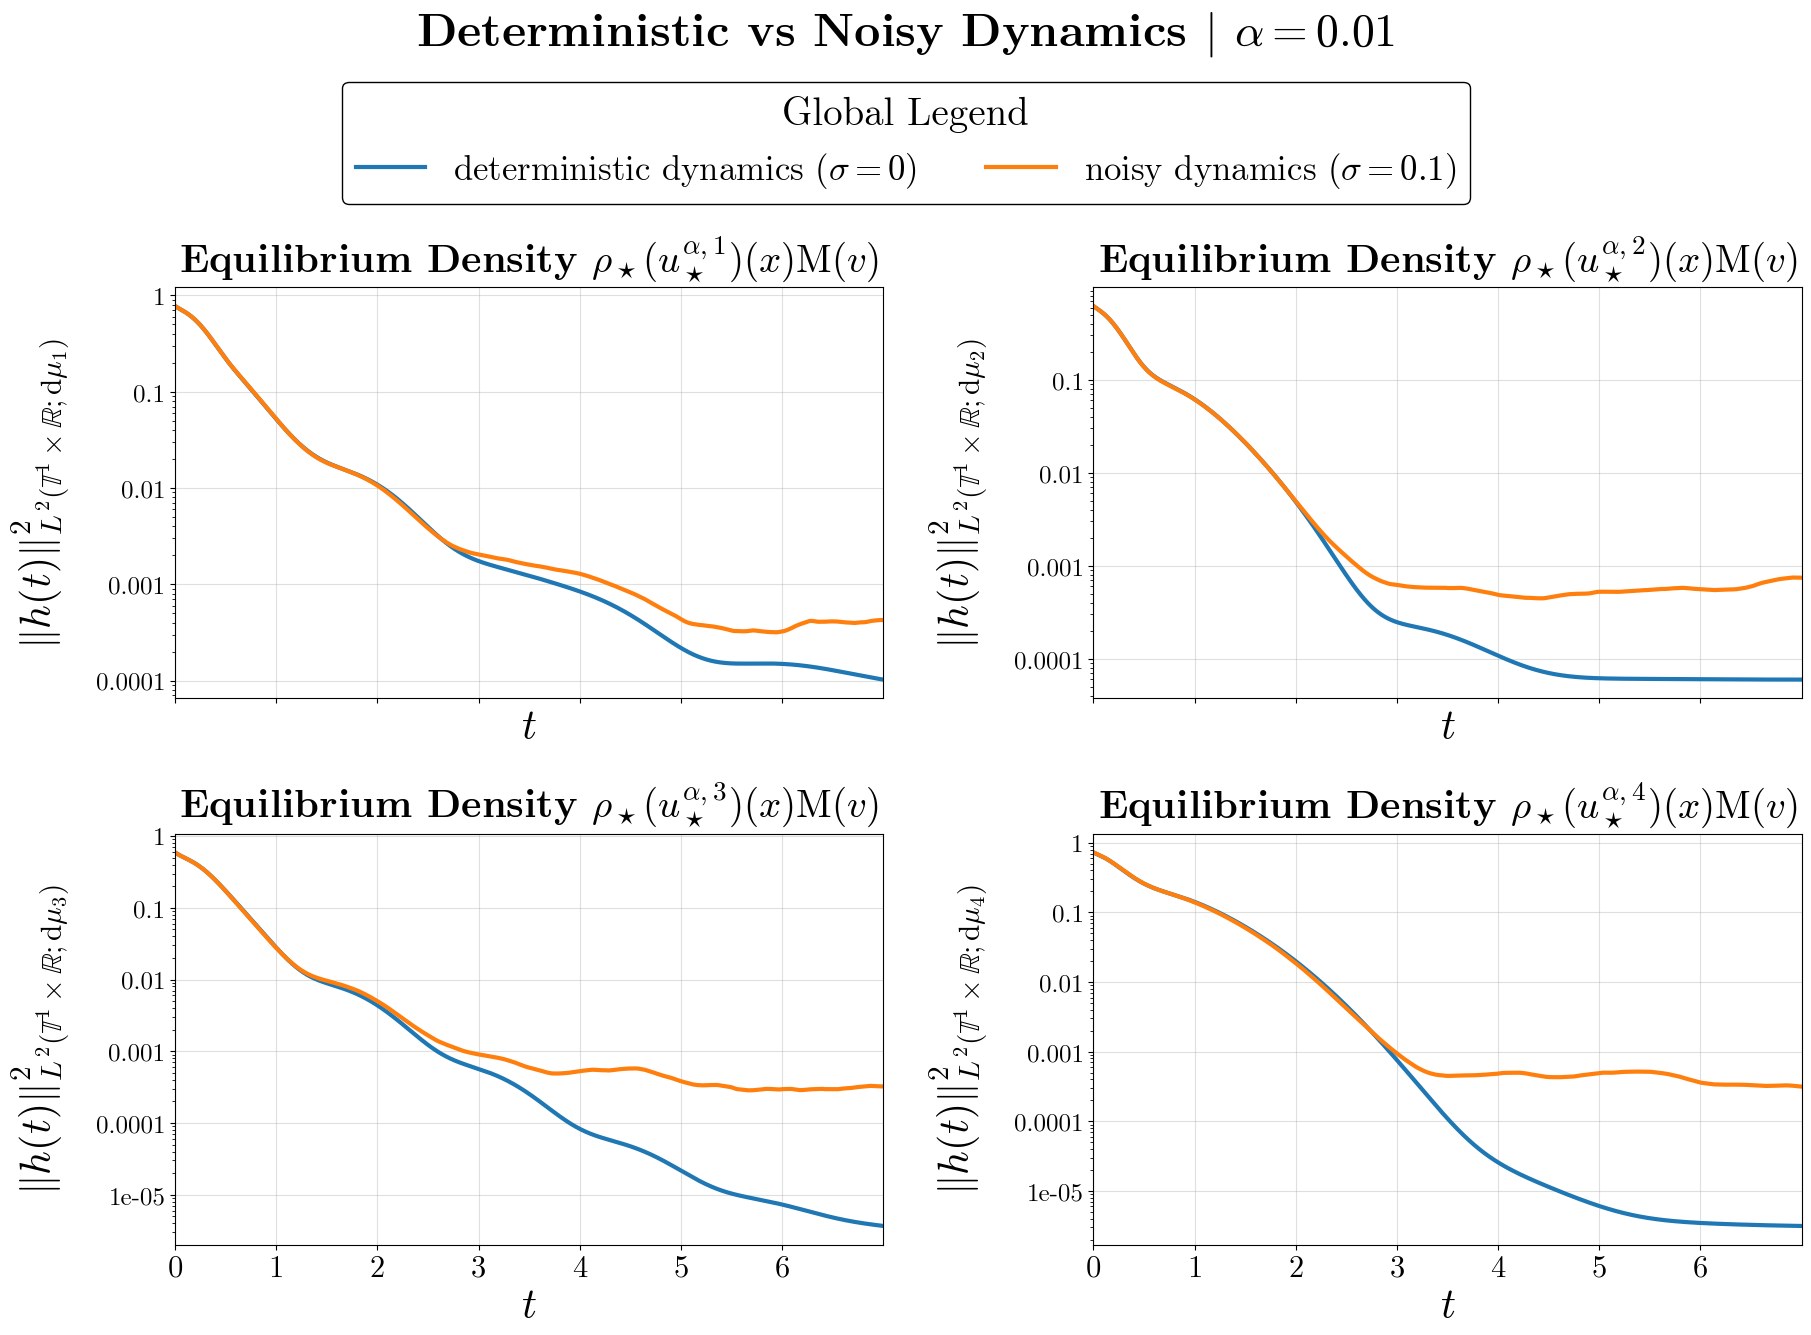

In [82]:
# ----------------------------------------------
# PLOTS - UNCONTROLLED DYNAMICS 
# ----------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 11),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

t = np.arange(steps // 50) * (50 * dt)

for i, ax in enumerate(axes):
    
    res = all_results[i]
    L2_det_u = res["L2_free"]
    L2_noisy_u = res["L2_free_noise"]

    ax.plot(t, L2_det_u,  linewidth=3.0,  label=rf"deterministic dynamics $(\sigma=0)$")
    ax.plot(t, L2_noisy_u, linewidth=3.0, label=rf"noisy dynamics $(\sigma={noise_amp})$")

    ax.set_yscale("log")
    ax.set_xlim(t.min(), t.max())

    ax.set_title(
        rf"Equilibrium Density $\rho_\star(u_\star^{{\alpha,{i+1}}})(x)\text{{M}}(v)$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$t$", fontsize=30)
    ax.set_ylabel(
        rf"$\|h(t)\|_{{L^2(\mathbb{{T}}^1\times\mathbb{{R}};\mathrm{{d}}\mu_{{{i+1}}})}}^2$",
        fontsize=30,
        labelpad=18
    )

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=4,
    fontsize=25,
    title_fontsize=28,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Deterministic vs Noisy Dynamics $|$ $\alpha = 0.01$",
    fontsize=33,
    x=0.5,
    y=1.2,
    fontweight="bold"
)

plt.show()

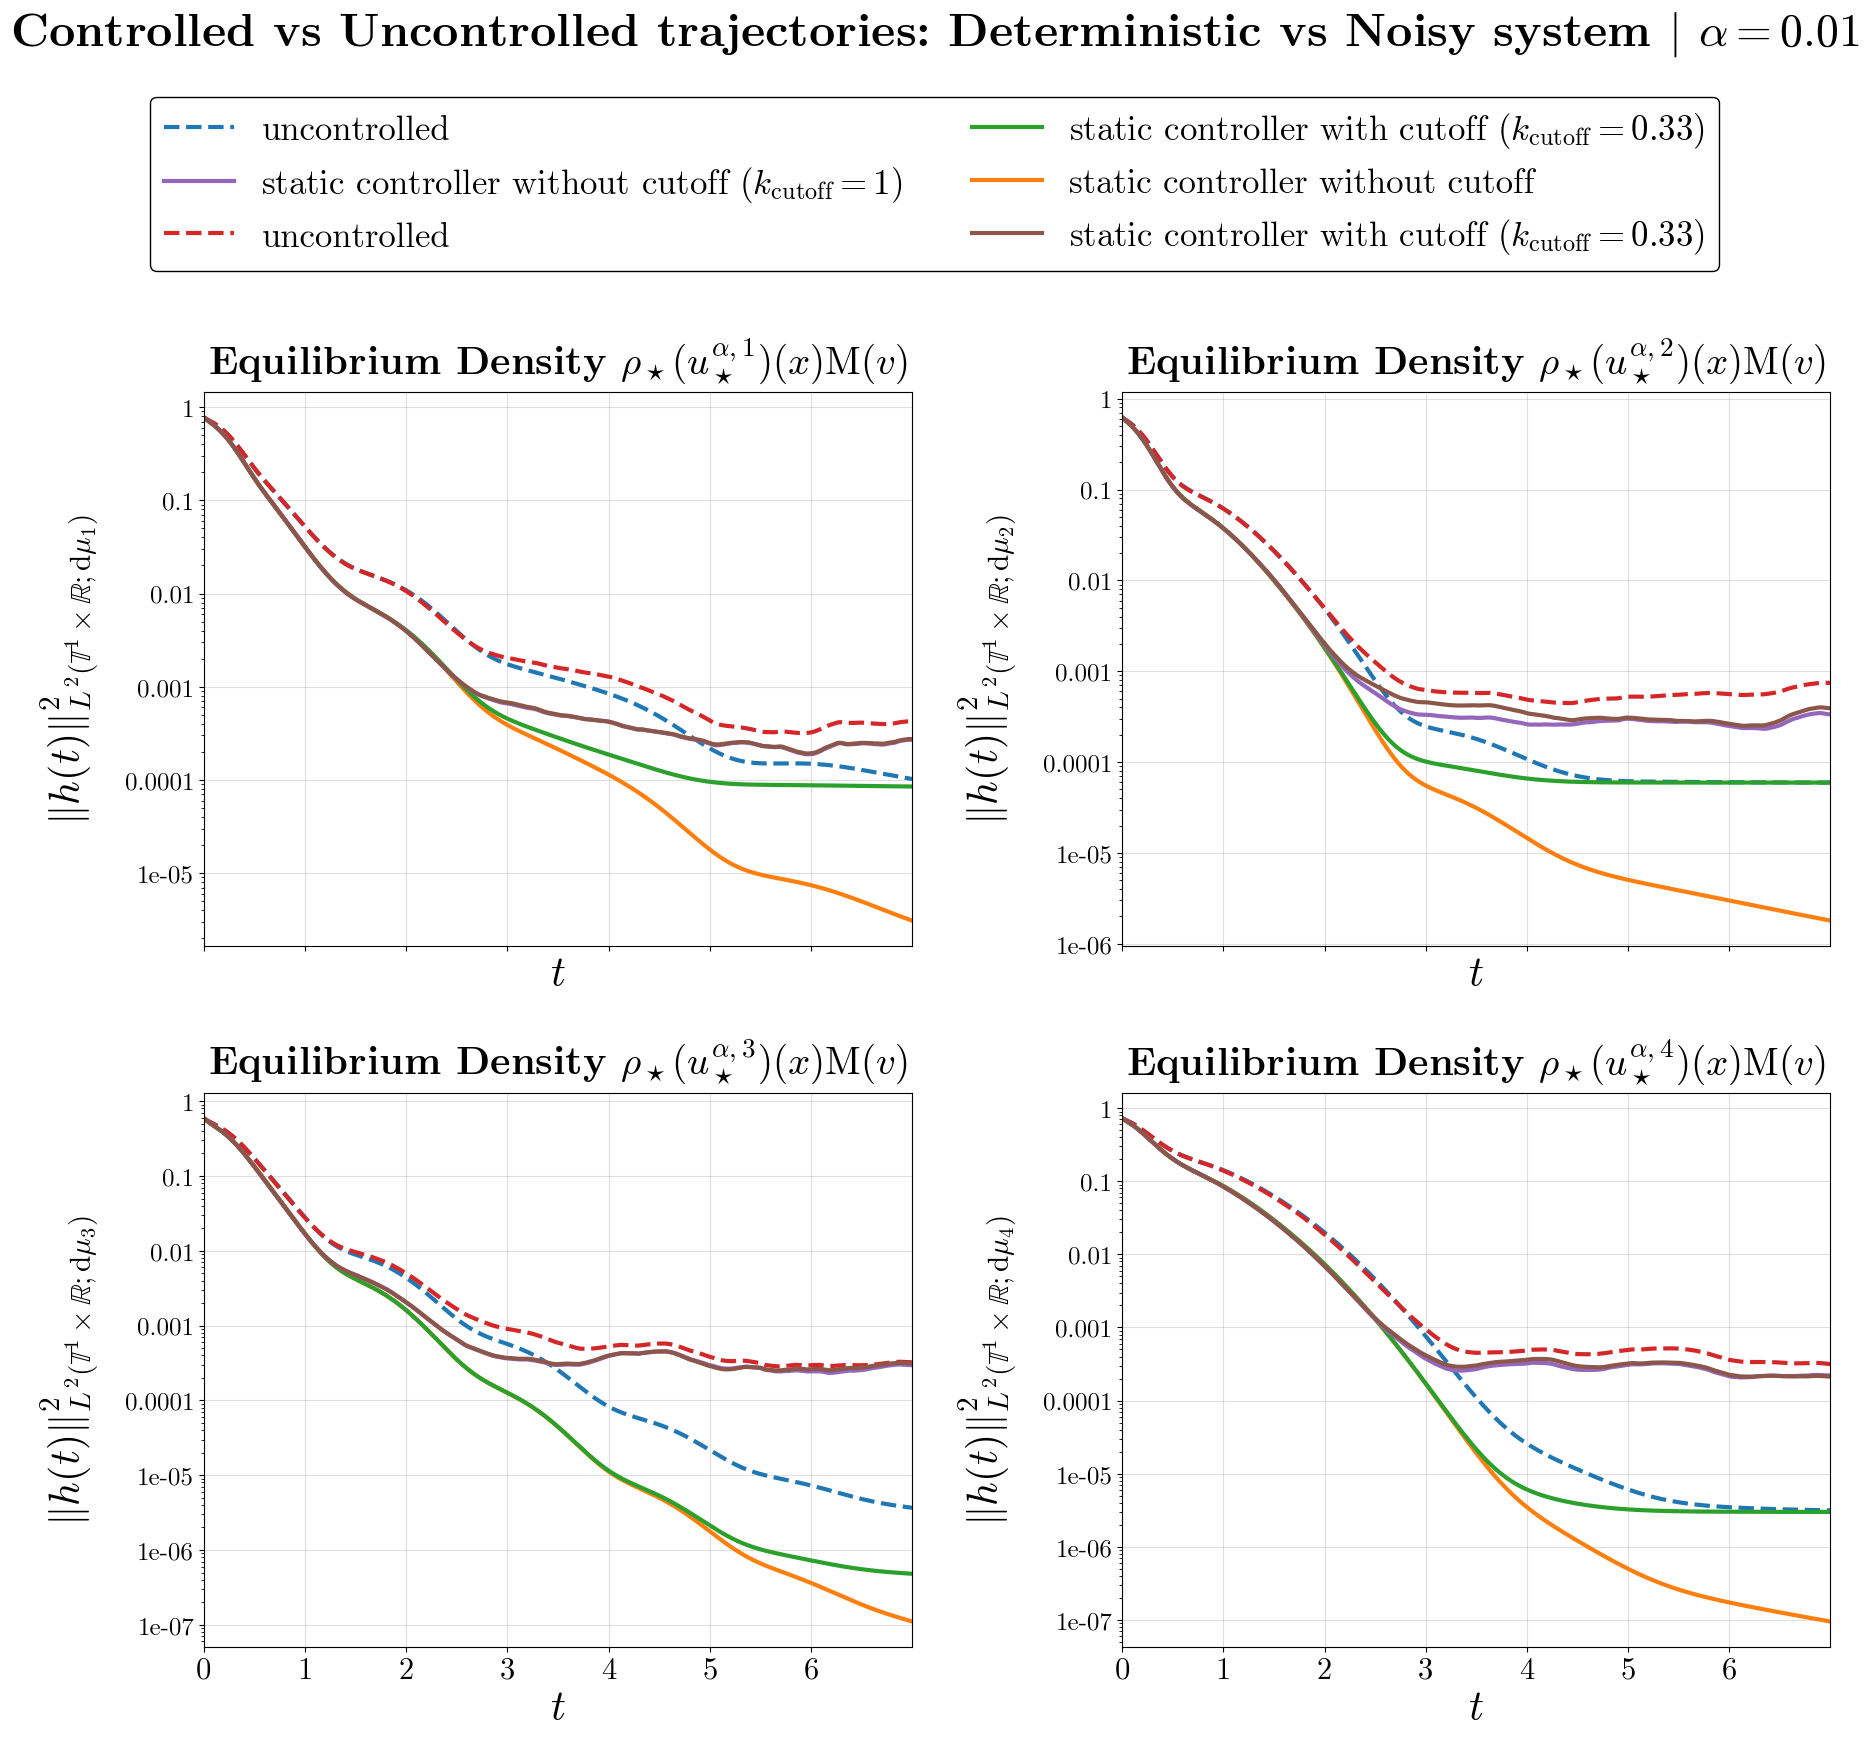

In [86]:
# --------------------------------------------------------------------------------------------
# PLOTS - CONTROLLED vs UNCONTROLLED - STATIC CONTROLLER WITH AND WITHOUT CUTOFF
# --------------------------------------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

t = np.arange(steps // 50) * (50 * dt)

for i, ax in enumerate(axes):
    res = all_results[i]

    L2_free = res["L2_free"]
    L2_static = res["L2_static"]
    L2_static_cutoff = res["L2_static_cutoff"]

    L2_free_noise = res["L2_free_noise"]
    L2_static_noise = res["L2_static_noise"]
    L2_static_cutoff_noise = res["L2_static_cutoff_noise"]

    ax.plot(t, L2_free,   linestyle="--", linewidth=3.0,  label=rf"uncontrolled")
    ax.plot(t, L2_static,   linestyle="-", linewidth=3.0,  label=r"static controller without cutoff")
    ax.plot(t, L2_static_cutoff,   linestyle="-", linewidth=3.0,  label=rf"static controller with cutoff $(k_{{\mathrm{{cutoff}}}}={cutoff_param})$")

    ax.plot(t, L2_free_noise,   linestyle="--", linewidth=3.0,  label=rf"uncontrolled")
    ax.plot(t, L2_static_noise,   linestyle="-", linewidth=3.0,  label=rf"static controller without cutoff $(k_{{\mathrm{{cutoff}}}}=1)$")
    ax.plot(t, L2_static_cutoff_noise,   linestyle="-", linewidth=3.0,  label=rf"static controller with cutoff $(k_{{\mathrm{{cutoff}}}}={cutoff_param})$")

    ax.set_yscale("log")
    ax.set_xlim(t.min(), t.max())

    ax.set_title(
        rf"Equilibrium Density $\rho_\star(u_\star^{{\alpha,{i+1}}})(x)\text{{M}}(v)$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$t$", fontsize=30)
    ax.set_ylabel(
        rf"$\|h(t)\|_{{L^2(\mathbb{{T}}^1\times\mathbb{{R}};\mathrm{{d}}\mu_{{{i+1}}})}}^2$",
        fontsize=30,
        labelpad=18
    )

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()
order = [0, 4, 3, 2, 1, 5]
handles = [handles[i] for i in order]
labels = [labels[i] for i in order]

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    fontsize=25,
    title_fontsize=28,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

# Column descriptions
fig.text(
    0.38, 1.155,
    r"Deterministic Dynamics $(\sigma=0)$",
    ha="center",
    va="center",
    fontsize=24,
    fontweight="bold"
)

fig.text(
    0.62, 1.155,
    rf"Noisy Dynamics $(\sigma={noise_amp})$",
    ha="center",
    va="center",
    fontsize=24,
    fontweight="bold"
)

fig.suptitle(
    r"Controlled vs Uncontrolled trajectories: Deterministic vs Noisy system $|$ $\alpha = 0.01$",
    fontsize=33,
    x=0.5,
    y=1.23,
    fontweight="bold"
)

plt.show()

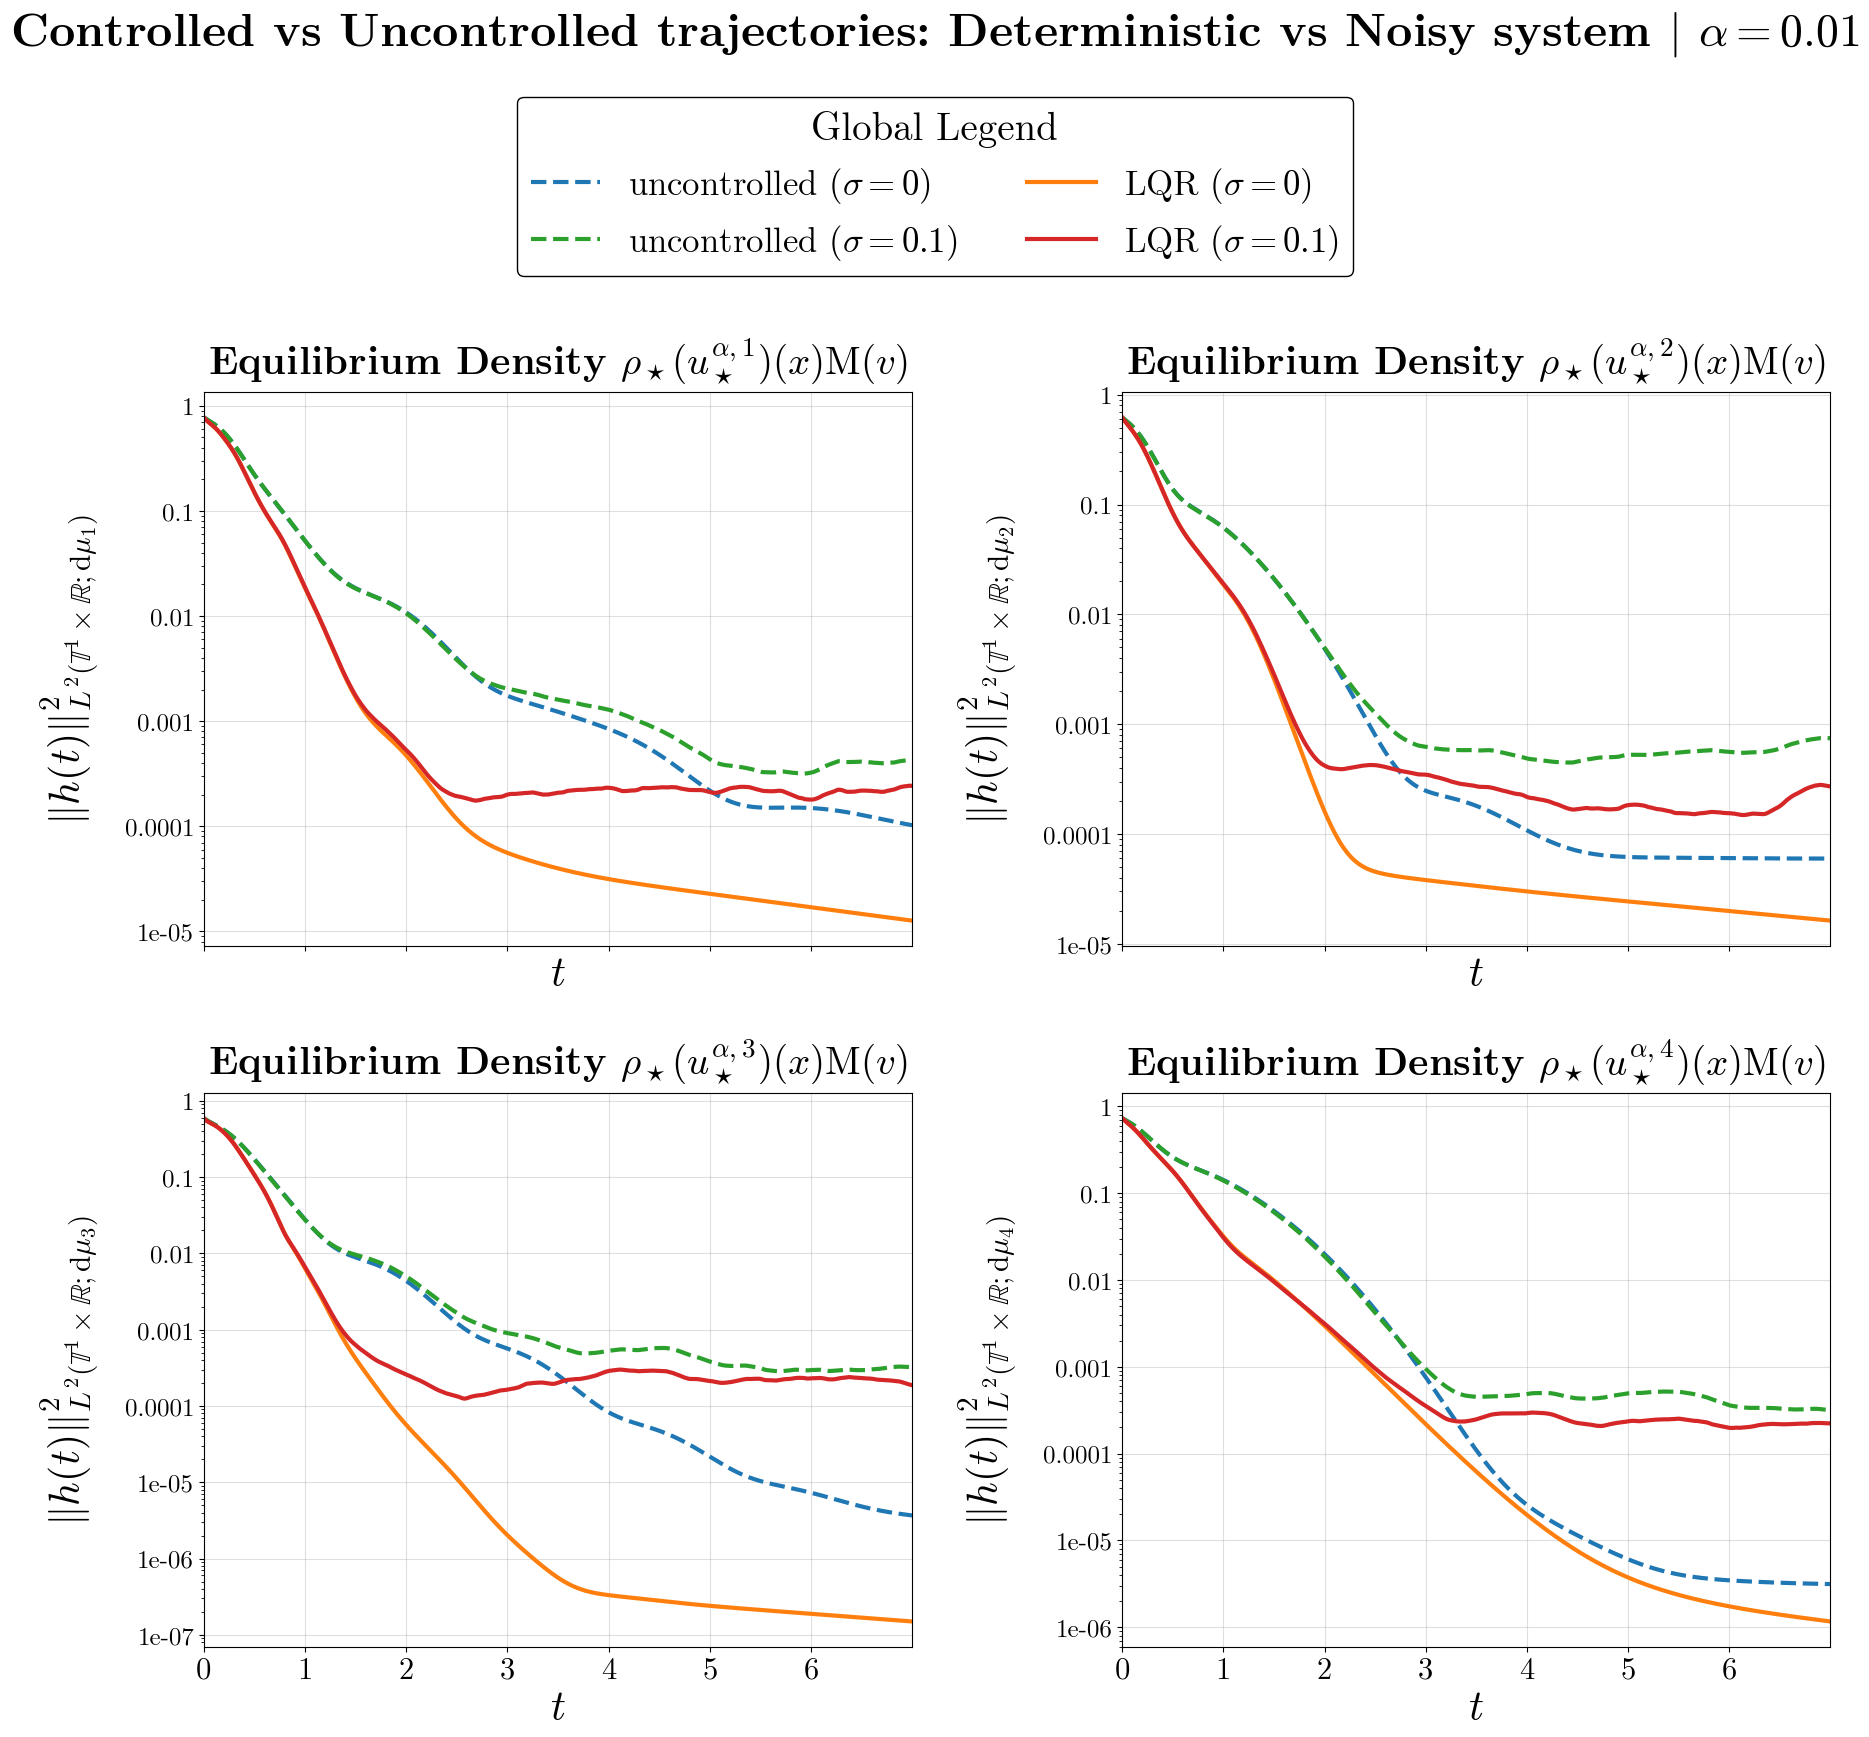

In [75]:
# --------------------------------------------------------------------------------------------
# PLOTS - CONTROLLED vs UNCONTROLLED - LQR CONTROLLER
# --------------------------------------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

t = np.arange(steps // 50) * (50 * dt)

for i, ax in enumerate(axes):
    res = all_results[i]

    L2_free = res["L2_free"]
    L2_lqr = res["L2_lqr"]

    L2_free_noise = res["L2_free_noise"]
    L2_lqr_noise = res["L2_lqr_noise"]

    ax.plot(t, L2_free,   linestyle="--", linewidth=3.0,  label=rf"uncontrolled $(\sigma=0)$")
    ax.plot(t, L2_lqr,   linestyle="-", linewidth=3.0,  label=rf"LQR $(\sigma=0)$")

    ax.plot(t, L2_free_noise,   linestyle="--", linewidth=3.0,  label=rf"uncontrolled $(\sigma={noise_amp})$")
    ax.plot(t, L2_lqr_noise,   linestyle="-", linewidth=3.0,  label=rf"LQR $(\sigma={noise_amp})$")

    ax.set_yscale("log")
    ax.set_xlim(t.min(), t.max())

    ax.set_title(
        rf"Equilibrium Density $\rho_\star(u_\star^{{\alpha,{i+1}}})(x)\text{{M}}(v)$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$t$", fontsize=30)
    ax.set_ylabel(
        rf"$\|h(t)\|_{{L^2(\mathbb{{T}}^1\times\mathbb{{R}};\mathrm{{d}}\mu_{{{i+1}}})}}^2$",
        fontsize=30,
        labelpad=18
    )

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()
order = [0, 2, 1, 3] 
handles = [handles[i] for i in order]
labels = [labels[i] for i in order]

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    fontsize=25,
    title_fontsize=28,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Controlled vs Uncontrolled trajectories: Deterministic vs Noisy system $|$ $\alpha = 0.01$",
    fontsize=33,
    x=0.5,
    y=1.23,
    fontweight="bold"
)

plt.show()

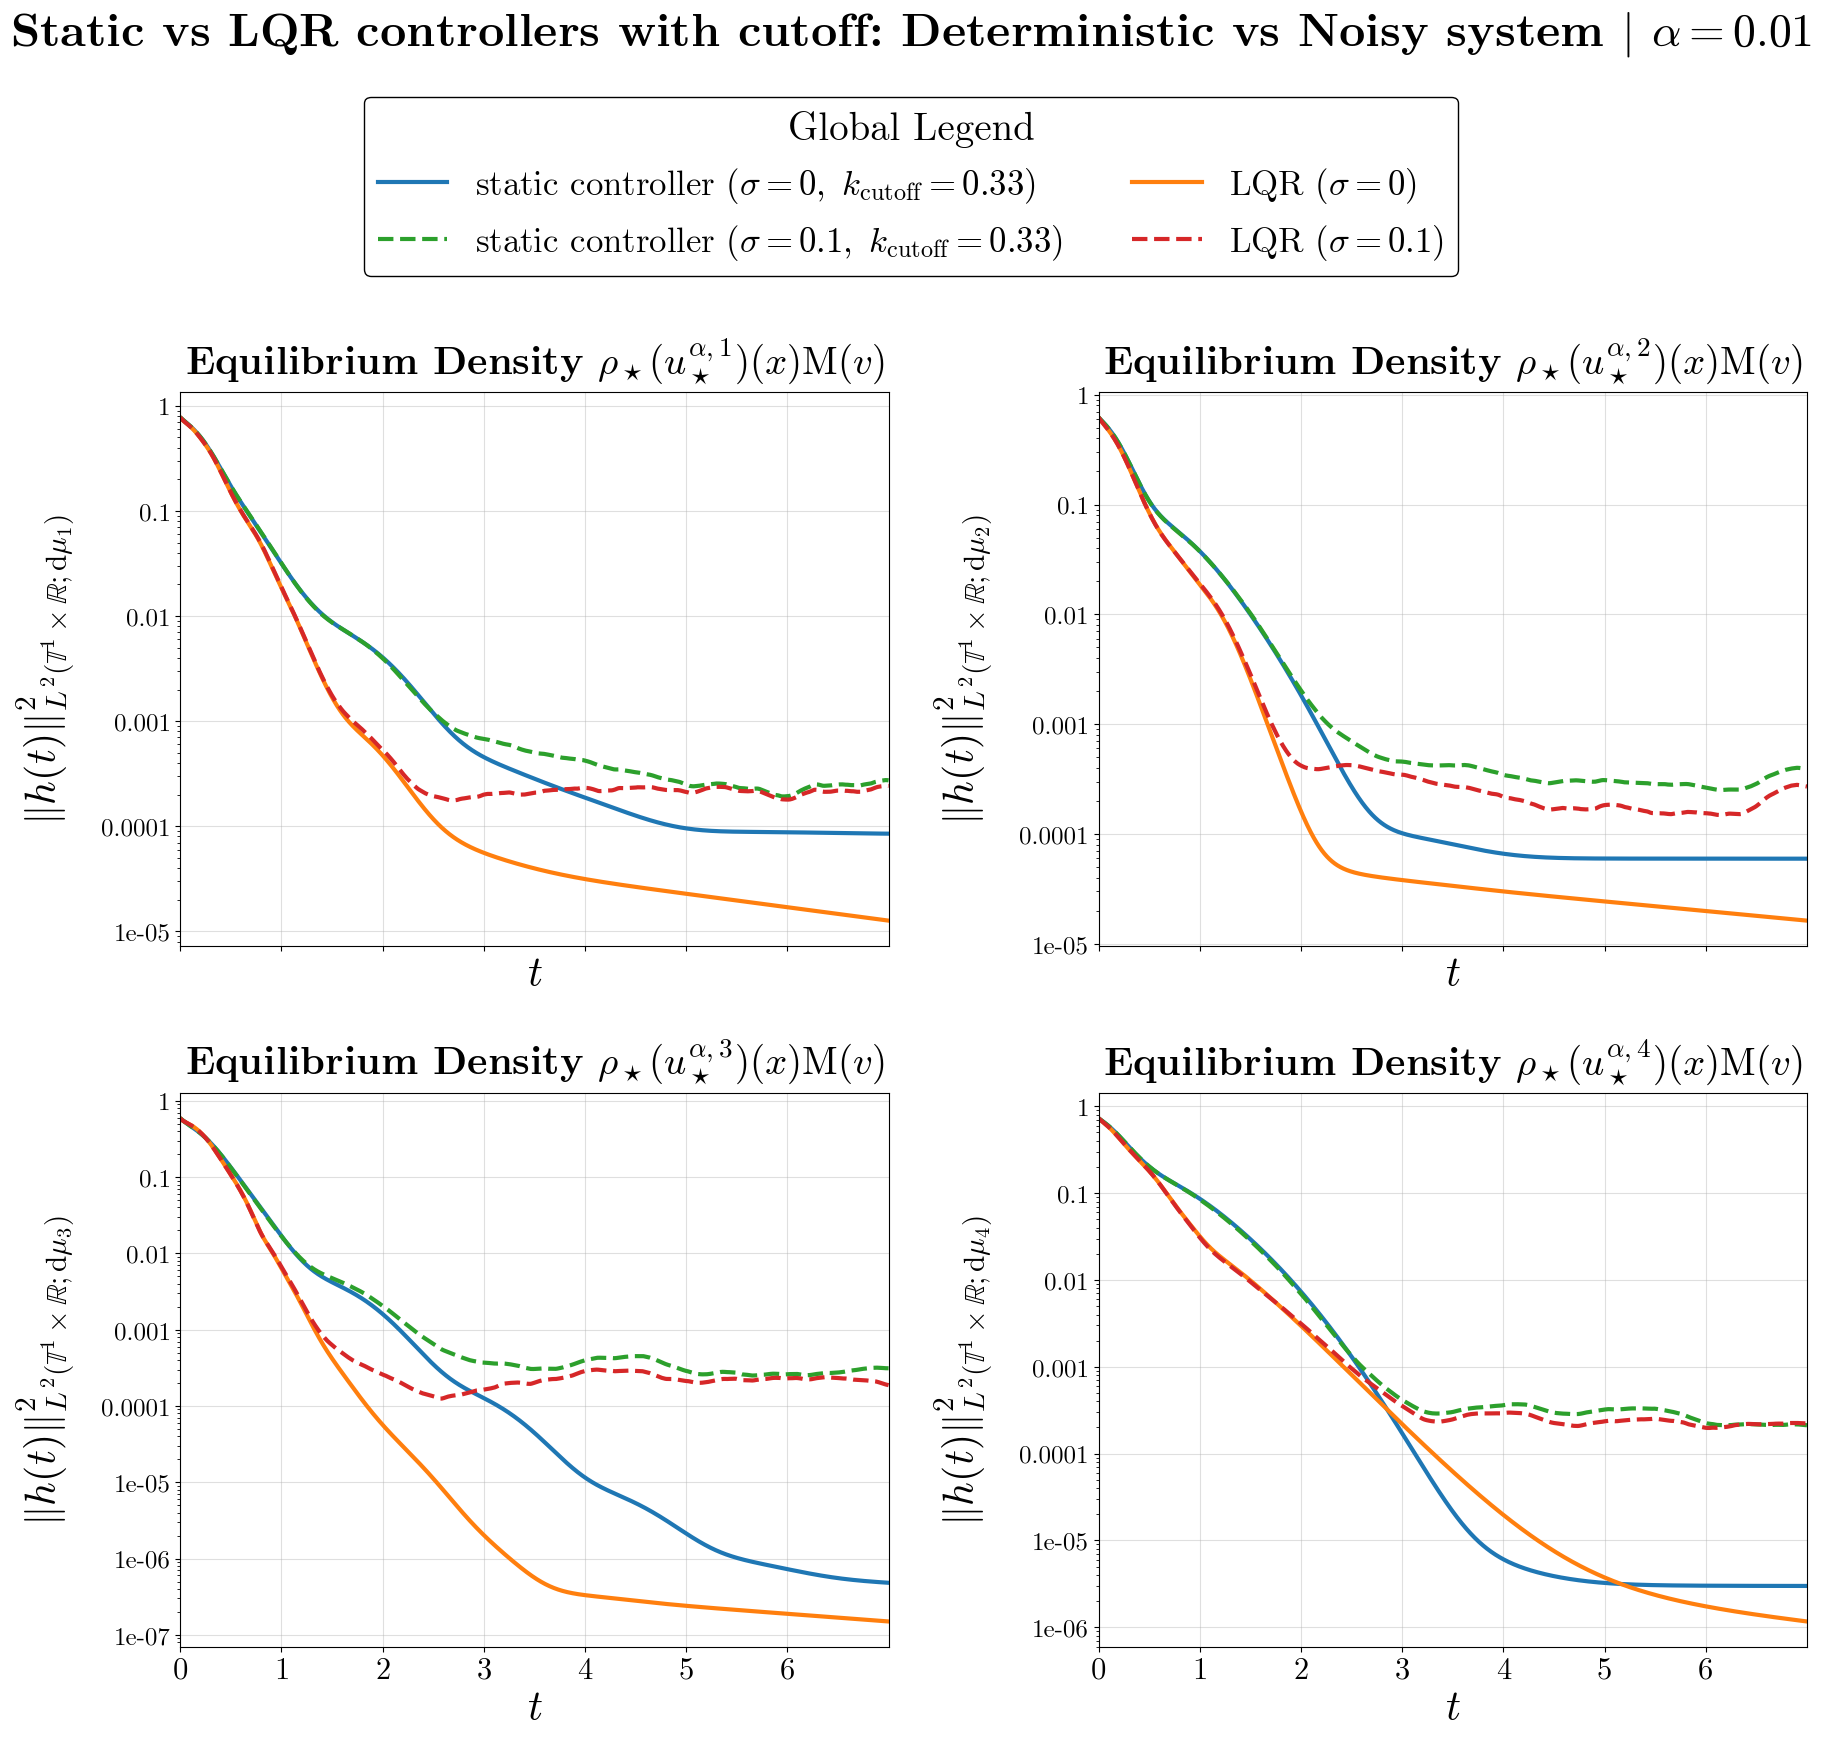

In [79]:
# --------------------------------------------------------------------------------------------
# PLOTS - CONTROLLED - STATIC CONTROLLER WITH AND WITHOUT CUTOFF VS LQR
# --------------------------------------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)
fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()

t = np.arange(steps // 50) * (50 * dt)

for i, ax in enumerate(axes):
    res = all_results[i]

    L2_static_cutoff = res["L2_static_cutoff"]
    L2_lqr = res["L2_lqr"]

    L2_static_cutoff_noise = res["L2_static_cutoff_noise"]
    L2_lqr_noise = res["L2_lqr_noise"]

    ax.plot(t, L2_static_cutoff,   linestyle="-", linewidth=3.0,  label=rf"static controller $(\sigma=0,\ k_{{\mathrm{{cutoff}}}}={cutoff_param})$")
    ax.plot(t, L2_lqr,   linestyle="-", linewidth=3.0,  label=rf"LQR $(\sigma=0)$")

    ax.plot(t, L2_static_cutoff_noise,   linestyle="--", linewidth=3.0,  label=rf"static controller $(\sigma={noise_amp},\ k_{{\mathrm{{cutoff}}}}={cutoff_param})$")
    ax.plot(t, L2_lqr_noise,   linestyle="--", linewidth=3.0,  label=rf"LQR $(\sigma={noise_amp})$")

    ax.set_yscale("log")
    ax.set_xlim(t.min(), t.max())

    ax.set_title(
        rf"Equilibrium Density $\rho_\star(u_\star^{{\alpha,{i+1}}})(x)\text{{M}}(v)$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(r"$t$", fontsize=30)
    ax.set_ylabel(
        rf"$\|h(t)\|_{{L^2(\mathbb{{T}}^1\times\mathbb{{R}};\mathrm{{d}}\mu_{{{i+1}}})}}^2$",
        fontsize=30,
        labelpad=18
    )

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

    ax.grid(True, alpha=0.4)

for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)

handles, labels = axes[0].get_legend_handles_labels()
order = [0, 2, 1, 3] 
handles = [handles[i] for i in order]
labels = [labels[i] for i in order]

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.18),
    ncol=2,
    fontsize=25,
    title_fontsize=28,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)

fig.suptitle(
    r"Static vs LQR controllers with cutoff: Deterministic vs Noisy system $|$ $\alpha = 0.01$",
    fontsize=33,
    x=0.5,
    y=1.23,
    fontweight="bold"
)

plt.show()

In [80]:
# --------------------------------------------------------------------------
# INTEGRATED DECAY RATES FOR THE DETERMINISTIC TRAJECTORIES
# --------------------------------------------------------------------------

def integrated_decay_rate(L2, dt_sample):

    t = np.arange(len(L2)) * dt_sample

    # avoid log(0)
    L2_safe = np.maximum(L2, 1e-300)

    # Lambda(t) = -0.5 * log(L2(t)/L2(0))
    Lambda = -0.5 * np.log(L2_safe / L2_safe[0])

    return t, Lambda

dt_sample = 50 * dt
integrated_rates = []

for result in all_results:

    int_rates = {}

    # uncontrolled
    int_rates["free"] = integrated_decay_rate(result["L2_free"], dt_sample)

    # static feedback without cutoff
    int_rates["static"] = integrated_decay_rate(result["L2_static"], dt_sample)

    # static feedback with cutoff
    int_rates["static_cutoff"] = integrated_decay_rate(result["L2_static_cutoff"], dt_sample)

    # LQR
    int_rates["lqr"] = integrated_decay_rate(result["L2_lqr"], dt_sample)

    integrated_rates.append(int_rates)

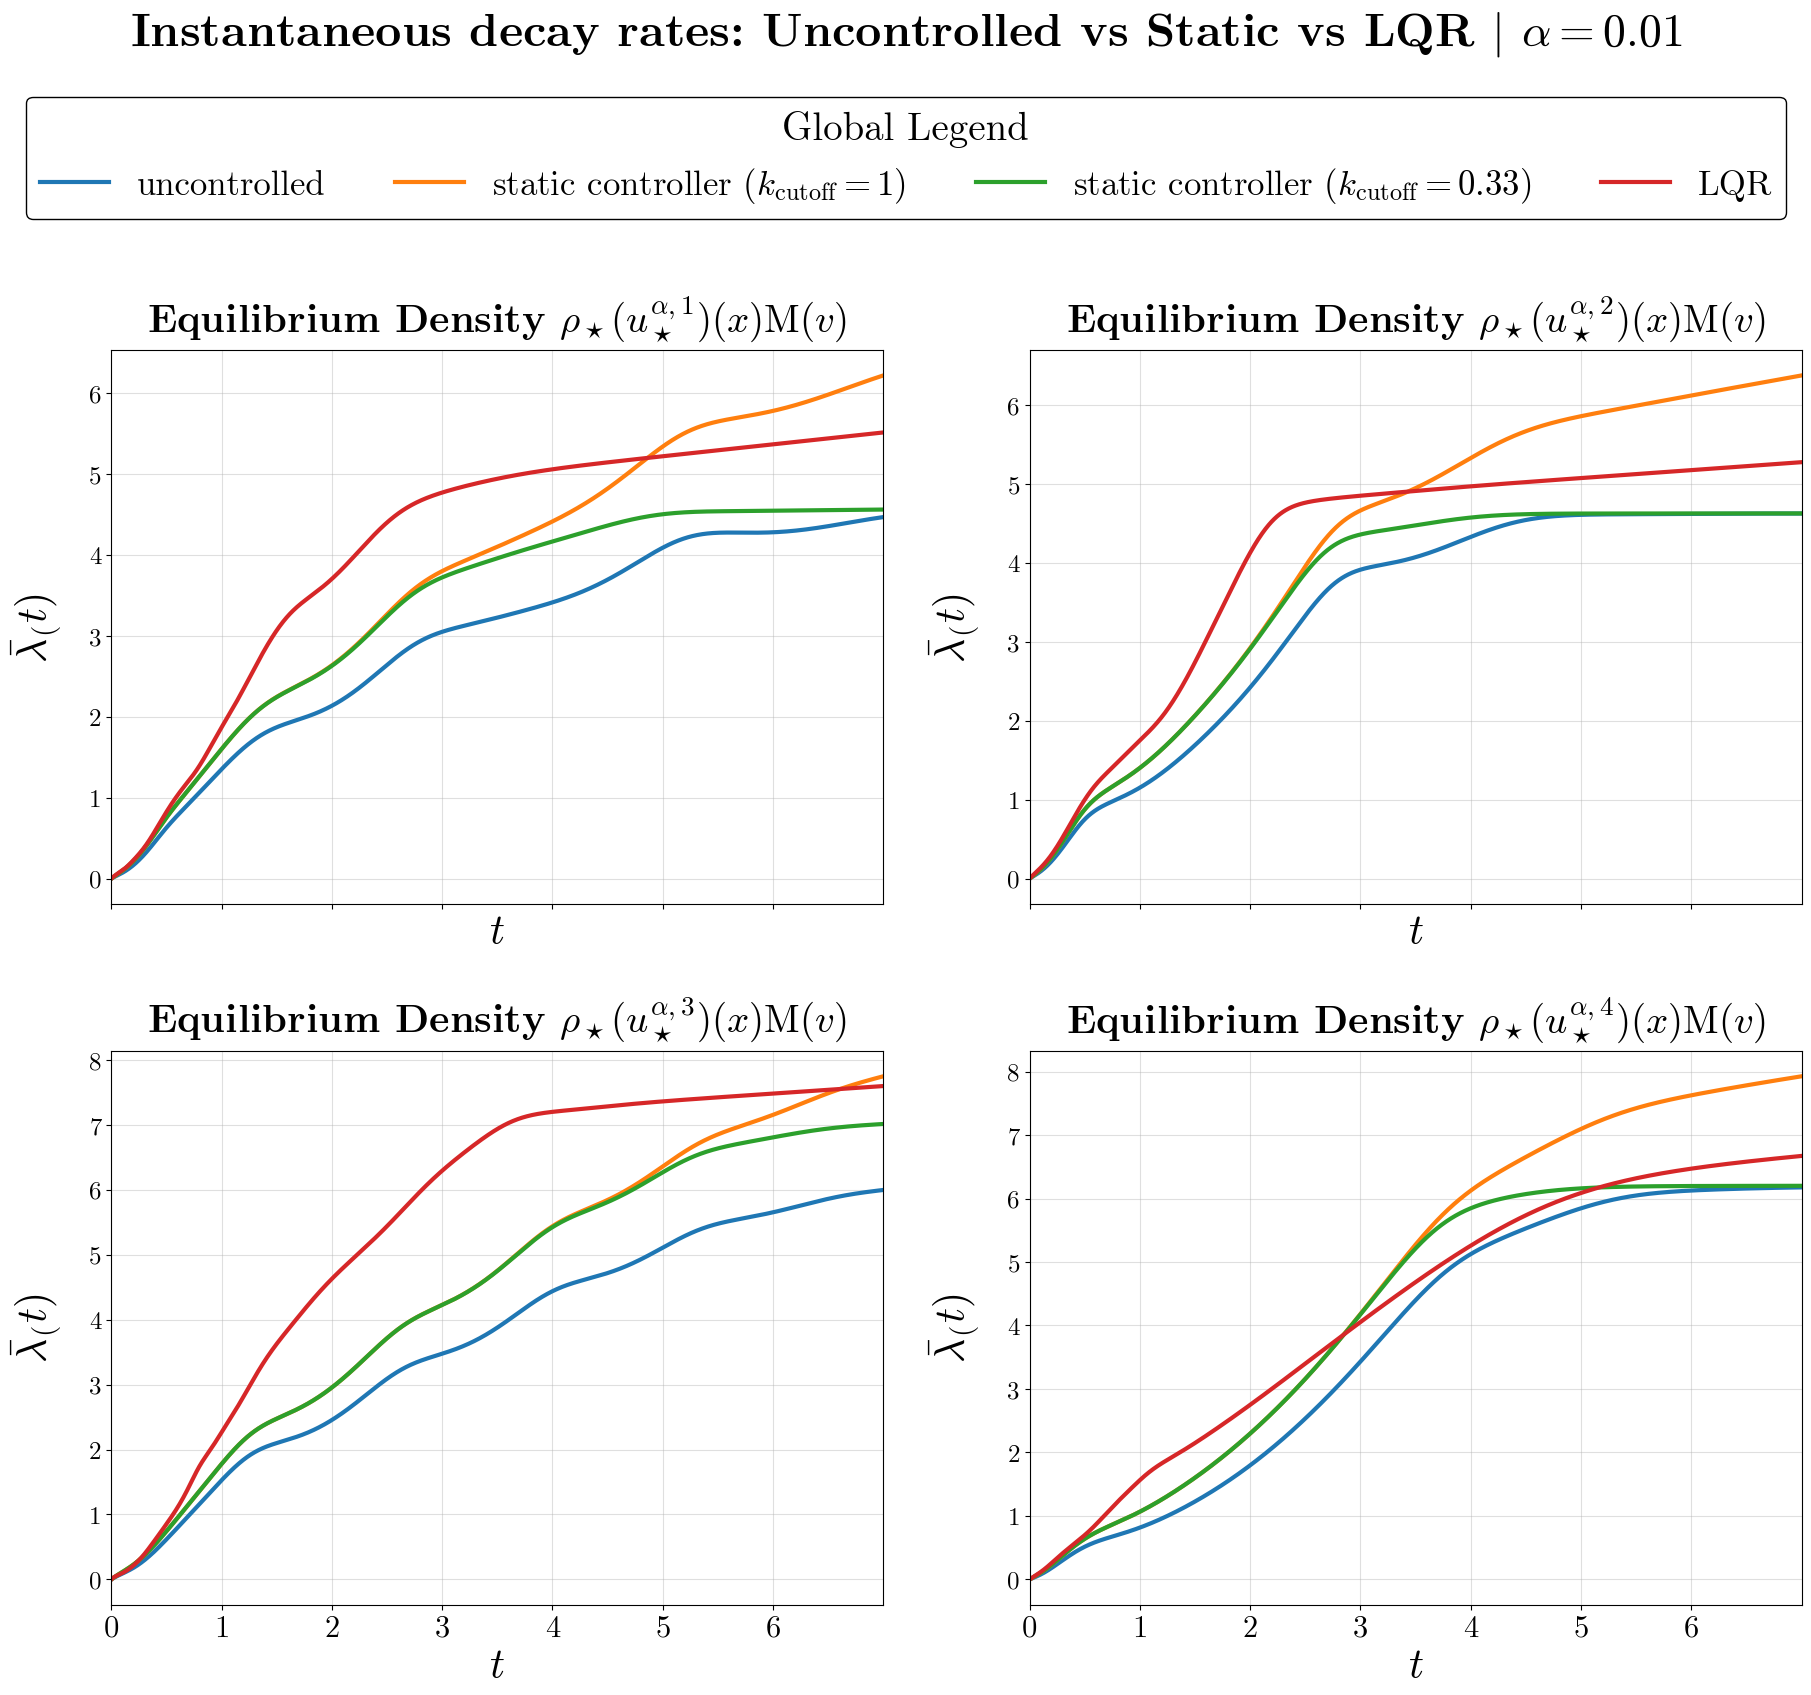

In [81]:
# --------------------------------------------------------------------------------------------
# PLOTS - INTEGRATED DECAY RATES - UNCONTROLLED VS STATIC VS LQR
# --------------------------------------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True,
    constrained_layout=True
)

fig.set_constrained_layout_pads(wspace=0.05, hspace=0.06)
axes = axes.ravel()


for i, ax in enumerate(axes):

    rates = integrated_rates[i]

    t_free, lam_free = rates["free"]
    t_static, lam_static = rates["static"]
    t_cutoff, lam_cutoff = rates["static_cutoff"]
    t_lqr, lam_lqr = rates["lqr"]


    ax.plot(t_free,lam_free,linestyle="-",linewidth=3.0,label=r"uncontrolled")
    ax.plot(t_static,lam_static,linestyle="-",linewidth=3.0,label=r"static controller $(k_{\mathrm{cutoff}}=1)$")
    ax.plot(t_cutoff,lam_cutoff,linestyle="-",linewidth=3.0,label=rf"static controller $(k_{{\mathrm{{cutoff}}}}={cutoff_param})$")
    ax.plot(t_lqr,lam_lqr,linestyle="-",linewidth=3.0,label=r"LQR")

    ax.set_xlim(t_free.min(), t_free.max())
    ax.set_title(
        rf"Equilibrium Density $\rho_\star(u_\star^{{\alpha,{i+1}}})(x)\mathrm{{M}}(v)$",
        fontsize=28,
        fontweight="bold",
        y=1.02
    )

    ax.set_xlabel(
        r"$t$",
        fontsize=30
    )

    ax.set_ylabel(
        r"$\bar{\lambda}_(t)$",
        fontsize=30,
        labelpad=18
    )

    ax.yaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(clean_fmt))

    ax.grid(True, alpha=0.4)


for ax in axes:
    ax.tick_params(axis='x', labelsize=22)
    ax.tick_params(axis='y', labelsize=18)


handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Global Legend",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=4,
    fontsize=25,
    title_fontsize=28,
    frameon=True,
    edgecolor="black",
    facecolor="white",
    framealpha=1.0,
)


fig.suptitle(
    r"Instantaneous decay rates: Uncontrolled vs Static vs LQR $|$ $\alpha = 0.01$",
    fontsize=33,
    x=0.5,
    y=1.20,
    fontweight="bold"
)

plt.show()